In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
from itertools import product
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize


In [2]:
def plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors,markers, title, start_date, end_date,spath):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dir in enumerate(datasets_dir):
        data[labels[k]]=xr.open_dataset(dir).sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'Total 2x2 flux, {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
            ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=labels[k])
            if parameters_uncertainty[k]!=False:
                ax[i].fill_between(data_sel.time, data_sel[parameters[k]]-data_sel[parameters_uncertainty[k]], data_sel[parameters[k]]+data_sel[parameters_uncertainty[k]], 
                               color=colors[k], alpha=0.2)        
        ax[i].legend()
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(-4e-7, 4e-7)
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [3]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]
# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [4]:
period='20201001-20220331'
analysis_start_date, analysis_end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
start_date, end_date =dt.date(2020,10,1), dt.date(2022,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/TM5'

In [5]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')
TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(TM54DVar_posterior_flux.time<=pd.to_datetime(analysis_end_date)),drop=True)

In [6]:
prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_prior_cut_weekly.nc')
prior=prior.where((prior.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(prior.time<=pd.to_datetime(analysis_end_date)),drop=True)

# only gosat no err inflation

In [7]:
period='20201001-20220331'
analysis_start_date, analysis_end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
start_date, end_date =dt.date(2020,10,1), dt.date(2022,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/TM5/different_errors/'

In [8]:
path='inversions_new/TM5_only_gosat_no_inflation'
correlations=['with']
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'


In [9]:
gosat_err=[1,2,3,5,10]
insitu_err=[2]
fluxes={}
gosat_data={}
tccon_data={}
insitu_data={}


In [10]:
for errors in gosat_err:
    print(errors)
    inversion_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/{errors}ppm_gosat_meas_err/'
    flux_path=f'{inversion_path}/20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc'
    fluxes[errors]=xr.open_dataset(flux_path)
    fluxes[errors]['time']=pd.to_datetime(fluxes[errors].time)
    fluxes[errors]=fluxes[errors].where((fluxes[errors].time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(fluxes[errors].time<=pd.to_datetime(analysis_end_date)),drop=True)

    gosat_data[errors]=xr.open_dataset(inversion_path+'gosat_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    gosat_data[errors]=gosat_data[errors].where((gosat_data[errors].release_time>=pd.to_datetime(analysis_start_date))&(gosat_data[errors].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    gosat_data[errors]=gosat_data[errors].where((gosat_data[errors].release_lat>analy_region_lat[0])&(gosat_data[errors].release_lat<analy_region_lat[1])&(gosat_data[errors].release_lon>analy_region_lon[0])&(gosat_data[errors].release_lon<analy_region_lon[1]),drop=True)

    tccon_data[errors]=xr.open_dataset(inversion_path+'TCCON_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    tccon_data[errors]=tccon_data[errors].where((tccon_data[errors].release_time>=pd.to_datetime(analysis_start_date))&(tccon_data[errors].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    tccon_data[errors]=tccon_data[errors].where((tccon_data[errors].release_lat>analy_region_lat[0])&(tccon_data[errors].release_lat<analy_region_lat[1])&(tccon_data[errors].release_lon>analy_region_lon[0])&(tccon_data[errors].release_lon<analy_region_lon[1]),drop=True)

    insitu_data[errors]=xr.open_dataset(inversion_path+'insitu_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    insitu_data[errors]=insitu_data[errors].where((insitu_data[errors].release_time>=pd.to_datetime(analysis_start_date))&(insitu_data[errors].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    insitu_data[errors]=insitu_data[errors].where((insitu_data[errors].release_lat>analy_region_lat[0])&(insitu_data[errors].release_lat<analy_region_lat[1])&(insitu_data[errors].release_lon>analy_region_lon[0])&(insitu_data[errors].release_lon<analy_region_lon[1]),drop=True)


1
2
3
5
10


<>:17: SyntaxWarning: invalid escape sequence '\o'
<>:17: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:46: SyntaxWarning: invalid escape sequence '\o'
<>:46: SyntaxWarning: invalid escape sequence '\s'
<>:17: SyntaxWarning: invalid escape sequence '\o'
<>:17: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:46: SyntaxWarning: invalid escape sequence '\o'
<>:46: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2035397/3378316541.py:17: SyntaxWarning: invalid escape sequence '\o'
  print(f'G_err={g_err}, $\overline{{d}}={d0}$,{d_abs=} $\sigma={d_std}$ N={len(temp.posterior_diff)}')
/tmp/ipykernel_2035397/3378316541.py:17: SyntaxWarning: invalid escape sequence '\s'
  print(f'G_err={g_err}, $\overline{{d}}={d0}$,{d_abs=} $\sigma={d_std}$ N={len(temp.posterior_diff)}')
/tmp/ipyke

insitu
G_err=1, $\overline{d}=-3.13$,d_abs=np.float64(5.6) $\sigma=7.59$ N=1775
GOSAT
G_err=1, $\overline{d}=-0.05$,d_abs=np.float64(1.66) $\sigma=2.41$ N=5729
TCCON
G_err=1, $\overline{d}=-1.01$,d_abs=np.float64(1.66) $\sigma=1.85$ N=973
insitu
G_err=2, $\overline{d}=-2.85$,d_abs=np.float64(5.27) $\sigma=7.22$ N=1775
GOSAT
G_err=2, $\overline{d}=-0.05$,d_abs=np.float64(1.68) $\sigma=2.44$ N=5729
TCCON
G_err=2, $\overline{d}=-1.01$,d_abs=np.float64(1.66) $\sigma=1.86$ N=973
insitu
G_err=3, $\overline{d}=-2.71$,d_abs=np.float64(5.12) $\sigma=7.05$ N=1775
GOSAT
G_err=3, $\overline{d}=-0.05$,d_abs=np.float64(1.69) $\sigma=2.45$ N=5729
TCCON
G_err=3, $\overline{d}=-1.01$,d_abs=np.float64(1.67) $\sigma=1.86$ N=973
insitu
G_err=5, $\overline{d}=-2.54$,d_abs=np.float64(4.97) $\sigma=6.86$ N=1775
GOSAT
G_err=5, $\overline{d}=-0.05$,d_abs=np.float64(1.7) $\sigma=2.47$ N=5729
TCCON
G_err=5, $\overline{d}=-1.02$,d_abs=np.float64(1.67) $\sigma=1.87$ N=973
insitu
G_err=10, $\overline{d}=-2.28$,d_ab

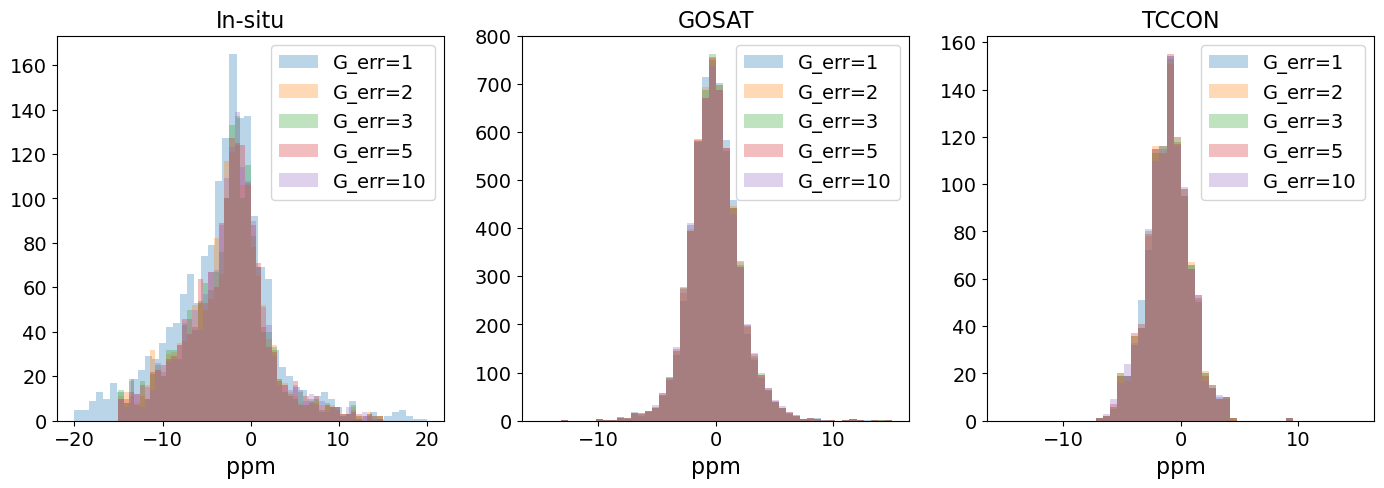

In [ ]:
nbins=50
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for g_err in gosat_err:
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    temp=insitu_data[g_err]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=f'G_err={g_err}'
    print('insitu')
    print(f'G_err={g_err}, $\overline{{d}}={d0}$,{d_abs=} $\sigma={d_std}$ N={len(temp.posterior_diff)}')
    axs[0].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[0].legend(fontsize=14)
    axs[0].set_xlabel('ppm',fontsize=16)
    axs[0].set_title(title[0],fontsize=16)
    axs[0].tick_params(labelsize =14)

    max_min=(-15,15)
    temp=gosat_data[g_err]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=f'G_err={g_err}'
    print('GOSAT')
    print(f'G_err={g_err}, $\overline{{d}}={d0}$,{d_abs=} $\sigma={d_std}$ N={len(temp.posterior_diff)}')
    axs[1].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[1].legend(fontsize=14)   
    axs[1].set_xlabel('ppm',fontsize=16)
    axs[1].set_title(title[1],fontsize=16)
    axs[1].tick_params(labelsize =14)

    
    max_min=(-15,15)
    temp=tccon_data[g_err]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=f'G_err={g_err}'
    print('TCCON')
    print(f'G_err={g_err}, $\overline{{d}}={d0}$,{d_abs=} $\sigma={d_std}$ N={len(temp.posterior_diff)}')    
    axs[2].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[2].legend(fontsize=14)    
    axs[2].set_xlabel('ppm',fontsize=16)
    axs[2].set_title(title[2],fontsize=16)
    axs[2].tick_params(labelsize =14)


plt.savefig(f'{savefig}/histogramm_diff_gosat_err_no_inflation.png')

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_885105/1729157893.py:30: SyntaxWarning: invalid escape sequence '\m'
  axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')


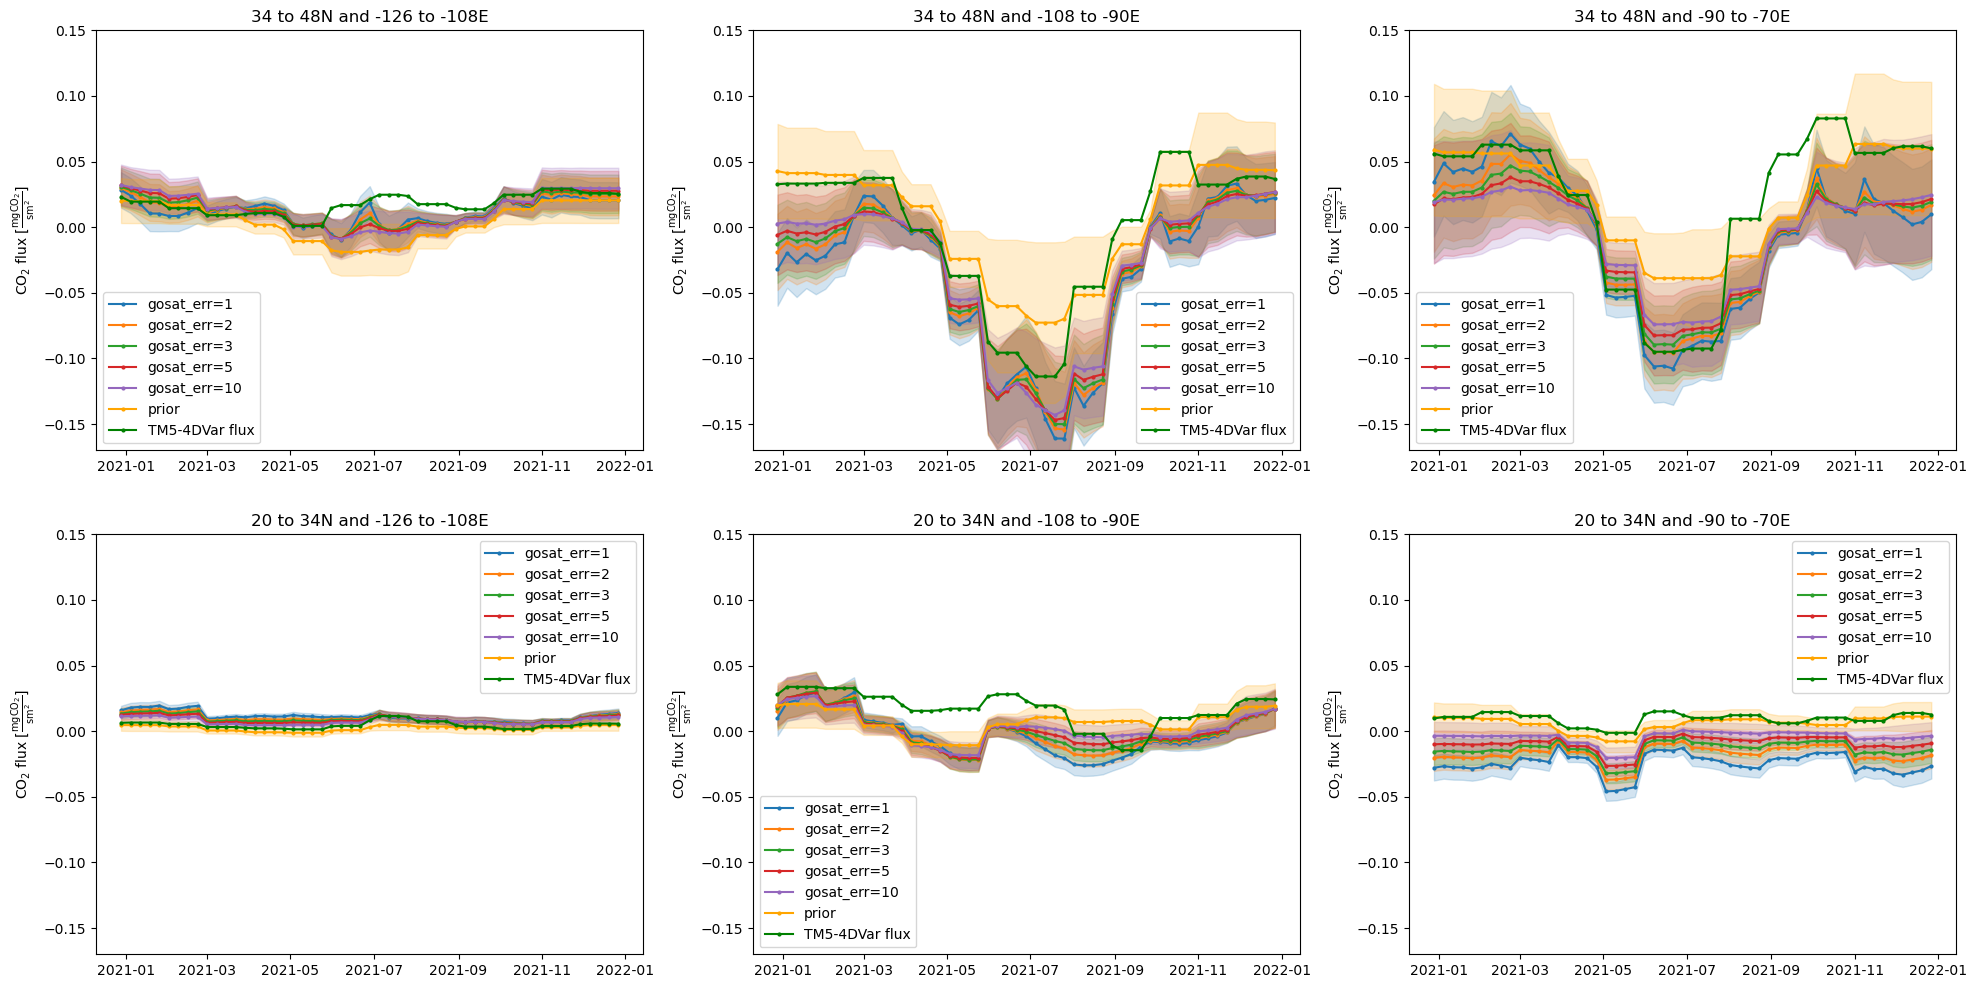

In [15]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        k=0
        for g_err in gosat_err:
            temp=fluxes[g_err]
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'gosat_err={g_err}')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6

        axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='orange', marker='o', markersize=2, label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='orange', alpha=0.2)  
        axs[i,j].plot(temp3.time, temp3.total_flux, c='green', marker='o', markersize=2, label='TM5-4DVar flux')

        axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')
        axs[i,j].legend()
        axs[i,j].set_ylim(-0.17,0.15)
        #axs[i,j].xticks(rotation=45)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        #axs[i,j].tight_layout()
plt.savefig(f'{savefig}/regional_fluxes_diff_gosat_err_no_inflation.png',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

In [16]:
prior_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err//{period}_{BG_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

colors=['orange','green']
marker=['x','x']
k=0
for errors in gosat_err:
    datasets_dir.append(f'{path}/2x2/with_correlation/footprint_spec001_mr/{errors}ppm_gosat_meas_err/{period}_{BG_ds}_bg.nc')
    labels.append(f'posterior g_err={errors}')
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')

print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'different GOSAT errors', start_date, end_date,savefig+'different_GOSAT_err_no_inflation_'+'2x2.png')


['TM5_prior_flux', 'total_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux']
['prior_uncertainty', False, 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std']
['orange', 'green', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
['x', 'x', 'o', 'o', 'o', 'o', 'o']
saved to: figures_2/TM5/different_errors/different_GOSAT_err_no_inflation_2x2.png


<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_374477/3768633948.py:25: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
/tmp/ipykernel_374477/3768633948.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


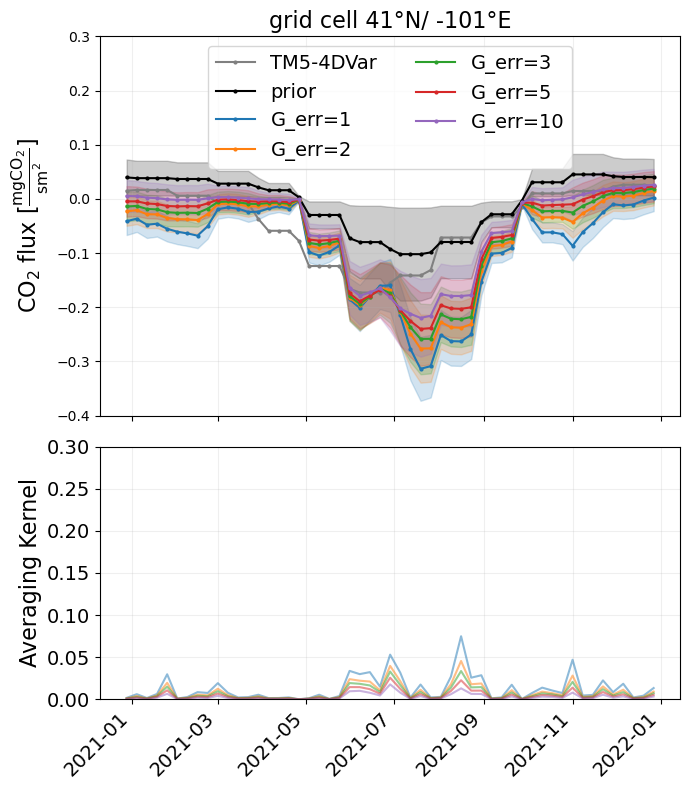

/tmp/ipykernel_374477/3768633948.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


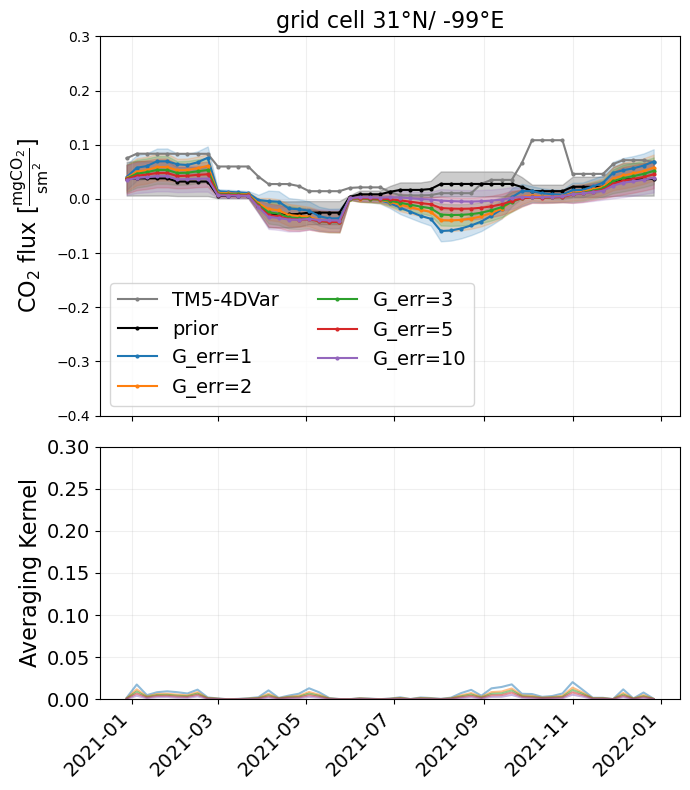

/tmp/ipykernel_374477/3768633948.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


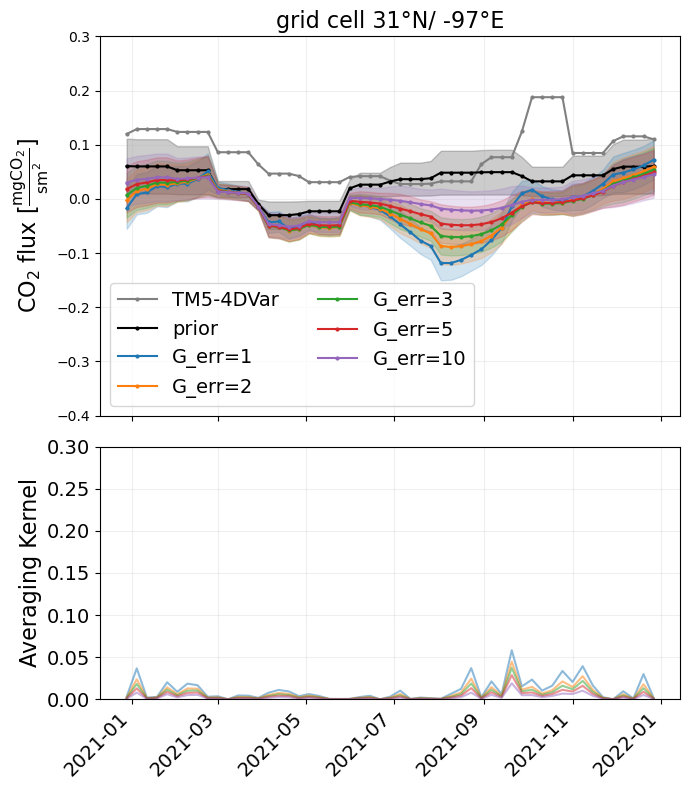

/tmp/ipykernel_374477/3768633948.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


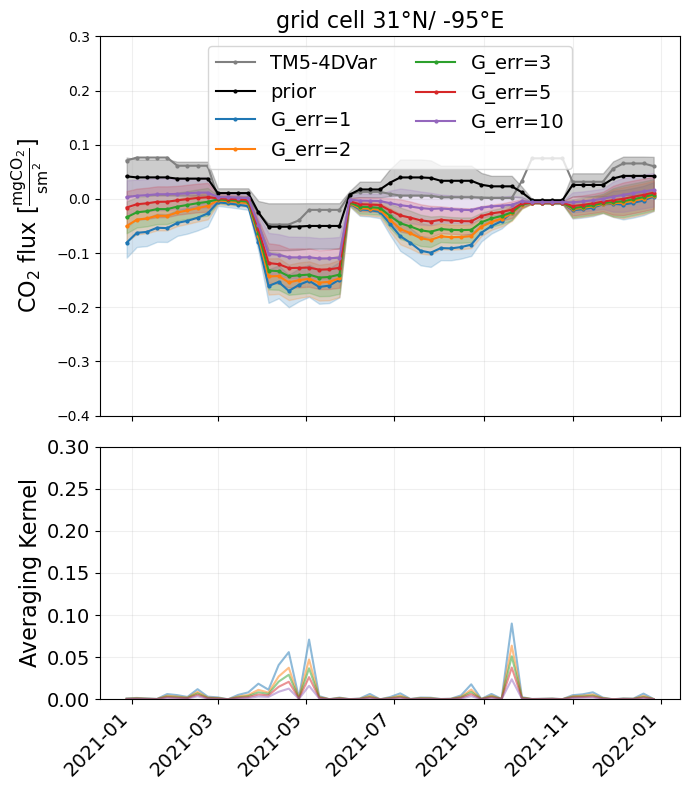

/tmp/ipykernel_374477/3768633948.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


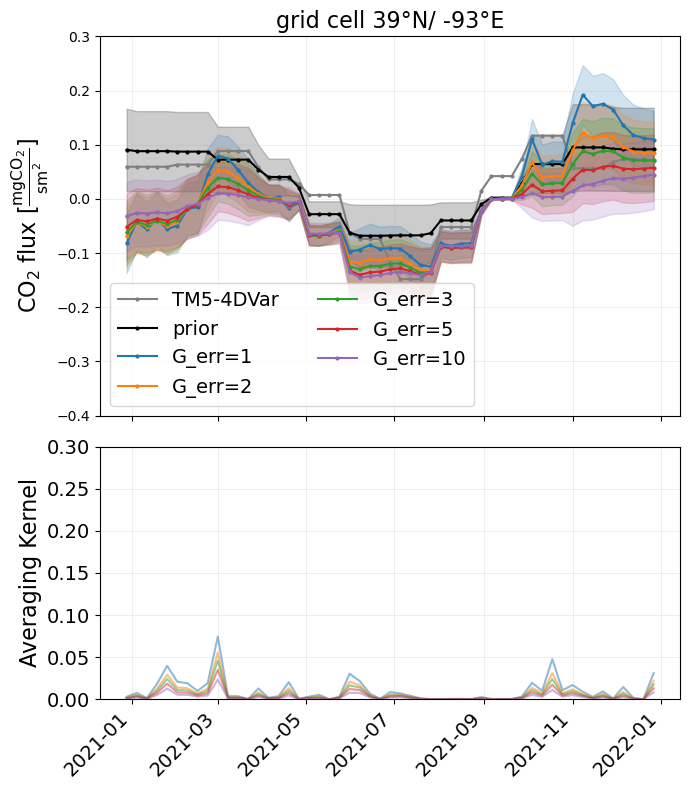

In [11]:
min,max=-0.4,0.3
lat_lon=[(41,-101),(31,-99),(31,-97),(31,-95),(39,-93)]
for lat,lon in lat_lon:
    fig,axs=plt.subplots(2,1,figsize=(7,8),gridspec_kw={'height_ratios': [3, 2]})
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    temp3=TM54DVar_posterior_flux.sel(latitude=lat,longitude=lon)
    temp3['total_flux']=temp3.total_flux*1e6
    axs[0].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar')
    k=0
    for g_err in gosat_err:
        temp=fluxes[g_err].sel(latitude=lat,longitude=lon)
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
        if k==0:
            axs[0].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
            axs[0].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2) 
        axs[0].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'G_err={g_err}')
        axs[0].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
        axs[1].plot(temp.time, temp.TM5_averaging_kernel_diag, color=default_colors[k], alpha=0.5)
        k+=1
    

    axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
    axs[0].legend(ncols=2,fontsize=14)
    axs[0].set_ylim(min,max)

    axs[0].tick_params(axis='x',labelbottom=False)
    axs[1].tick_params(axis='x', labelrotation=45,labelsize =14)
    plt.yticks(fontsize=14)
    axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')

    axs[0].grid(visible=True, which='major', axis='both', alpha=0.2)
    axs[1].grid(visible=True, which='major', axis='both', alpha=0.2)

    axs[1].set_ylabel('Averaging Kernel',fontsize=16)  # we already handled the x-label with ax1
    axs[1].tick_params(axis='y')
    axs[0].set_title(f"grid cell {lat}°N/ {lon}°E",fontsize=16)
    axs[1].set_ylim(0,0.3)
            #axs[i,j].tight_layout()
    plt.tight_layout()
    plt.savefig(f'{savefig}/only_gosat_no_inflation/girdbox_{lat}lat_{lon}lon.pdf',bbox_inches='tight')#,transparent=True)
    plt.show()

# only gosat err inflation

In [16]:
path='inversions_new/TM5_only_gosat'
correlations=['with']
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'


In [17]:
gosat_err=[1,2,3,5,10]
insitu_err=[2]
fluxes={}
gosat_data={}
tccon_data={}
insitu_data={}


In [18]:
for errors in gosat_err:
    print(errors)
    inversion_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/{errors}ppm_gosat_meas_err/'
    flux_path=f'{inversion_path}/20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc'
    fluxes[errors]=xr.open_dataset(flux_path)
    fluxes[errors]['time']=pd.to_datetime(fluxes[errors].time)
    fluxes[errors]=fluxes[errors].where((fluxes[errors].time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(fluxes[errors].time<=pd.to_datetime(analysis_end_date)),drop=True)

    gosat_data[errors]=xr.open_dataset(inversion_path+'gosat_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    gosat_data[errors]=gosat_data[errors].where((gosat_data[errors].release_time>=pd.to_datetime(analysis_start_date))&(gosat_data[errors].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    gosat_data[errors]=gosat_data[errors].where((gosat_data[errors].release_lat>analy_region_lat[0])&(gosat_data[errors].release_lat<analy_region_lat[1])&(gosat_data[errors].release_lon>analy_region_lon[0])&(gosat_data[errors].release_lon<analy_region_lon[1]),drop=True)

    tccon_data[errors]=xr.open_dataset(inversion_path+'TCCON_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    tccon_data[errors]=tccon_data[errors].where((tccon_data[errors].release_time>=pd.to_datetime(analysis_start_date))&(tccon_data[errors].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    tccon_data[errors]=tccon_data[errors].where((tccon_data[errors].release_lat>analy_region_lat[0])&(tccon_data[errors].release_lat<analy_region_lat[1])&(tccon_data[errors].release_lon>analy_region_lon[0])&(tccon_data[errors].release_lon<analy_region_lon[1]),drop=True)

    insitu_data[errors]=xr.open_dataset(inversion_path+'insitu_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    insitu_data[errors]=insitu_data[errors].where((insitu_data[errors].release_time>=pd.to_datetime(analysis_start_date))&(insitu_data[errors].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    insitu_data[errors]=insitu_data[errors].where((insitu_data[errors].release_lat>analy_region_lat[0])&(insitu_data[errors].release_lat<analy_region_lat[1])&(insitu_data[errors].release_lon>analy_region_lon[0])&(insitu_data[errors].release_lon<analy_region_lon[1]),drop=True)


1
2
3
5
10


In [19]:
savefig

'figures_2/TM5/different_errors/'

<>:17: SyntaxWarning: invalid escape sequence '\o'
<>:17: SyntaxWarning: invalid escape sequence '\o'
<>:17: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:46: SyntaxWarning: invalid escape sequence '\o'
<>:46: SyntaxWarning: invalid escape sequence '\o'
<>:46: SyntaxWarning: invalid escape sequence '\s'
<>:17: SyntaxWarning: invalid escape sequence '\o'
<>:17: SyntaxWarning: invalid escape sequence '\o'
<>:17: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:46: SyntaxWarning: invalid escape sequence '\o'
<>:46: SyntaxWarning: invalid escape sequence '\o'
<>:46: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3745970/3638102669.py:17: SyntaxWarning: invalid escape sequence '\

insitu
G_err=1, $\overline{d}=-3.1$,  $\overline{|d|}=5.58$, $\sigma=7.56$ N=1775
GOSAT
G_err=1, $\overline{d}=-0.05$, $\overline{|d|}=1.68$, $\sigma=2.44$ N=5729
TCCON
G_err=1, $\overline{d}=-1.01$, $\overline{|d|}=1.66$, $\sigma=1.85$ N=973
insitu
G_err=2, $\overline{d}=-2.82$,  $\overline{|d|}=5.27$, $\sigma=7.2$ N=1775
GOSAT
G_err=2, $\overline{d}=-0.05$, $\overline{|d|}=1.7$, $\sigma=2.47$ N=5729
TCCON
G_err=2, $\overline{d}=-1.01$, $\overline{|d|}=1.67$, $\sigma=1.86$ N=973
insitu
G_err=3, $\overline{d}=-2.66$,  $\overline{|d|}=5.11$, $\sigma=6.99$ N=1775
GOSAT
G_err=3, $\overline{d}=-0.05$, $\overline{|d|}=1.71$, $\sigma=2.48$ N=5729
TCCON
G_err=3, $\overline{d}=-1.02$, $\overline{|d|}=1.67$, $\sigma=1.86$ N=973
insitu
G_err=5, $\overline{d}=-2.45$,  $\overline{|d|}=4.88$, $\sigma=6.69$ N=1775
GOSAT
G_err=5, $\overline{d}=-0.06$, $\overline{|d|}=1.73$, $\sigma=2.49$ N=5729
TCCON
G_err=5, $\overline{d}=-1.04$, $\overline{|d|}=1.68$, $\sigma=1.87$ N=973
insitu
G_err=10, $\overline

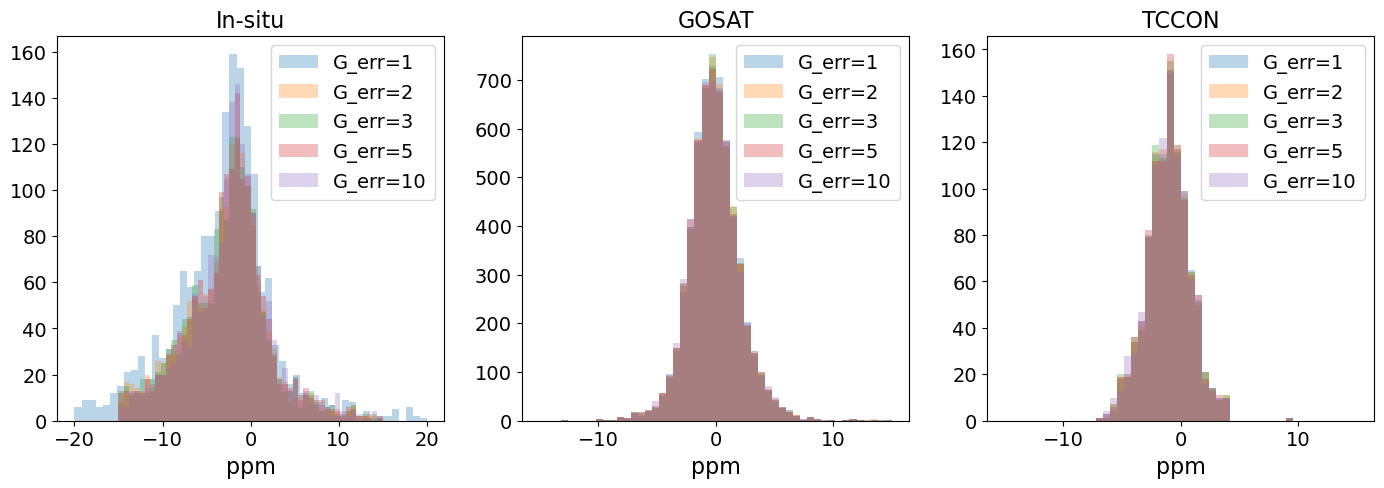

In [20]:
nbins=50
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for g_err in gosat_err:
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    temp=insitu_data[g_err]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=f'G_err={g_err}'
    print('insitu')
    print(f'G_err={g_err}, $\overline{{d}}={d0}$,  $\overline{{|d|}}={d_abs}$, $\sigma={d_std}$ N={len(temp.posterior_diff)}')
    axs[0].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[0].legend(fontsize=14)
    axs[0].set_xlabel('ppm',fontsize=16)
    axs[0].set_title(title[0],fontsize=16)
    axs[0].tick_params(labelsize =14)

    max_min=(-15,15)
    temp=gosat_data[g_err]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=f'G_err={g_err}'
    print('GOSAT')
    print(f'G_err={g_err}, $\overline{{d}}={d0}$, $\overline{{|d|}}={d_abs}$, $\sigma={d_std}$ N={len(temp.posterior_diff)}')
    axs[1].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[1].legend(fontsize=14)   
    axs[1].set_xlabel('ppm',fontsize=16)
    axs[1].set_title(title[1],fontsize=16)
    axs[1].tick_params(labelsize =14)

    
    max_min=(-15,15)
    temp=tccon_data[g_err]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=f'G_err={g_err}'
    print('TCCON')
    print(f'G_err={g_err}, $\overline{{d}}={d0}$, $\overline{{|d|}}={d_abs}$, $\sigma={d_std}$ N={len(temp.posterior_diff)}')    
    axs[2].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[2].legend(fontsize=14)    
    axs[2].set_xlabel('ppm',fontsize=16)
    axs[2].set_title(title[2],fontsize=16)
    axs[2].tick_params(labelsize =14)


plt.savefig(f'{savefig}/histogramm_diff_gosat_err_with_inflation.pdf',dpi=500)

<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_885105/3832560838.py:31: SyntaxWarning: invalid escape sequence '\m'
  axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')


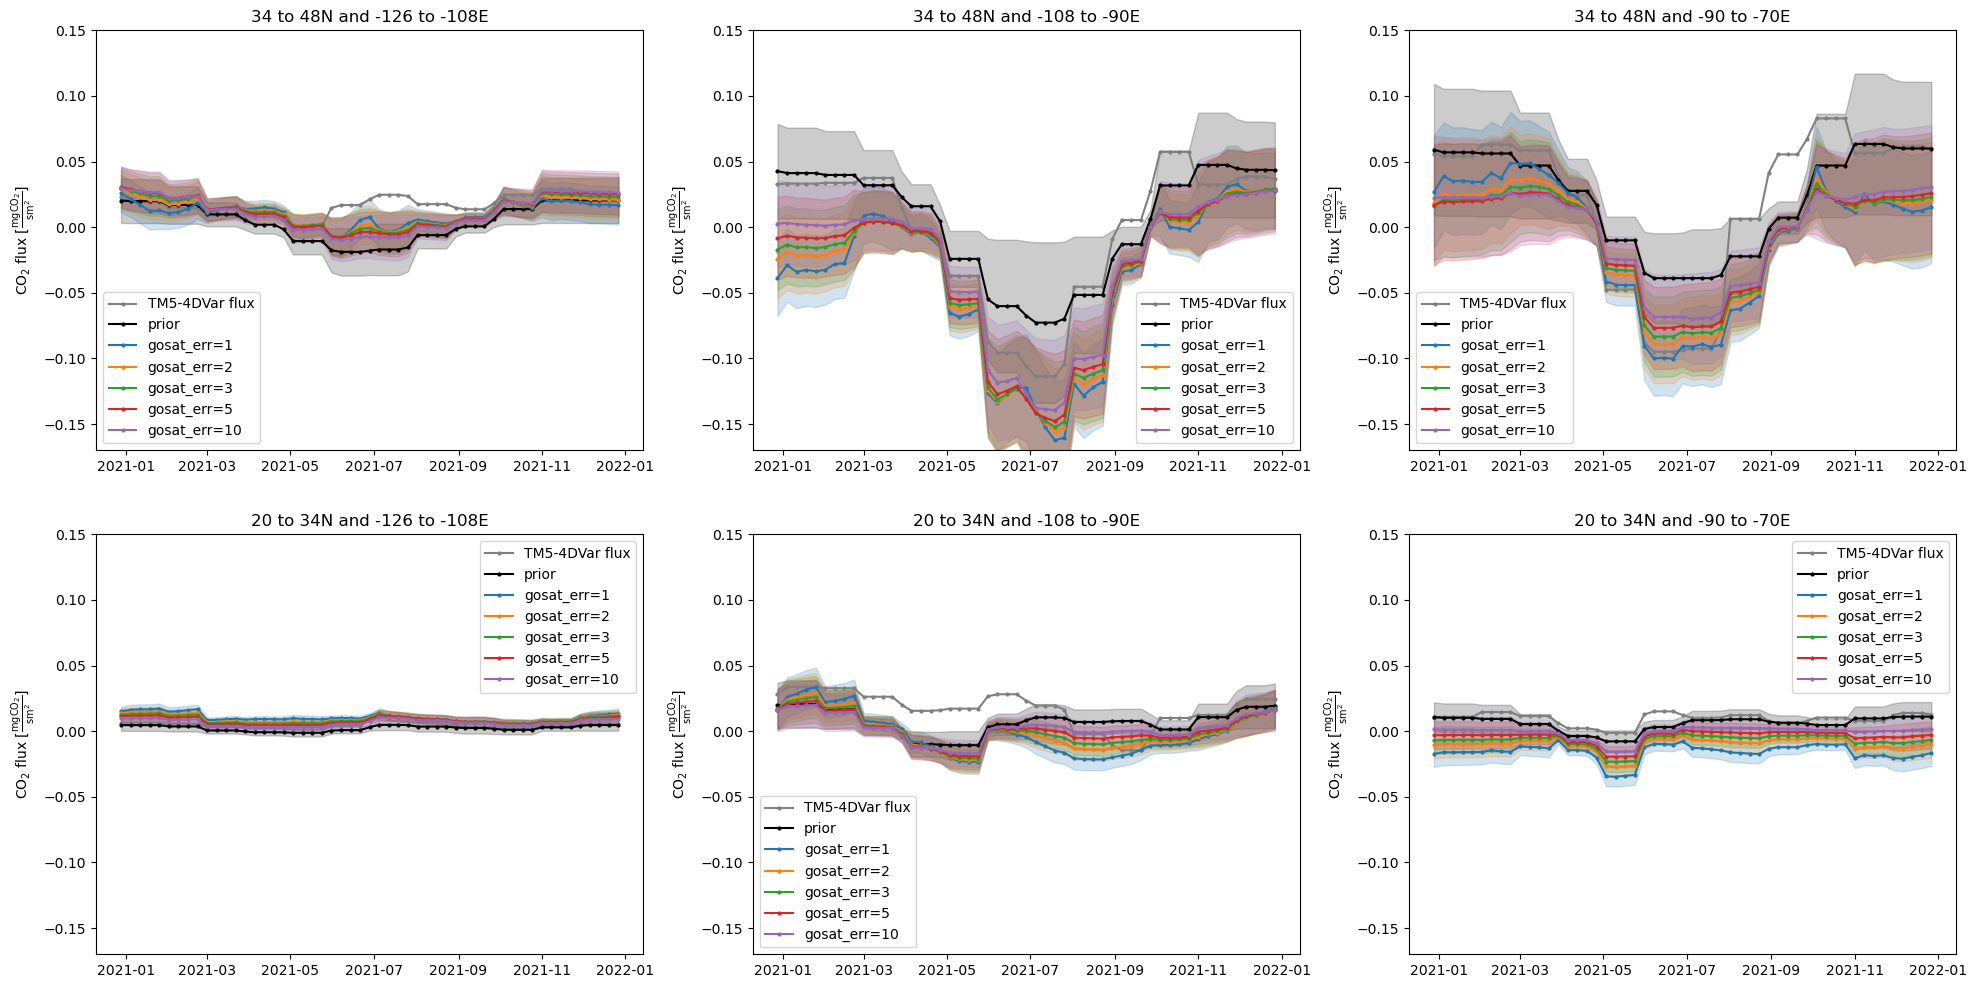

In [22]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        
        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')

        k=0
        for g_err in gosat_err:
            temp=fluxes[g_err]
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            if k==0:
                axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
                axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2)  
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'gosat_err={g_err}')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')
        axs[i,j].legend()
        axs[i,j].set_ylim(-0.17,0.15)
        #axs[i,j].xticks(rotation=45)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        #axs[i,j].tight_layout()
plt.savefig(f'{savefig}/regional_fluxes_diff_gosat_err_with inflation.png',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

In [23]:
prior_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err//{period}_{BG_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

colors=['orange','green']
marker=['x','x']
k=0
for errors in gosat_err:
    datasets_dir.append(f'{path}/2x2/with_correlation/footprint_spec001_mr/{errors}ppm_gosat_meas_err/{period}_{BG_ds}_bg.nc')
    labels.append(f'posterior g_err={errors}')
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')

print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'different GOSAT errors', start_date, end_date,savefig+'different_GOSAT_err_with_inflation_'+'2x2.png')


['TM5_prior_flux', 'total_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux']
['prior_uncertainty', False, 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std']
['orange', 'green', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
['x', 'x', 'o', 'o', 'o', 'o', 'o']
saved to: figures_2/TM5/different_errors/different_GOSAT_err_with_inflation_2x2.png


<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3745970/1667248467.py:27: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
/tmp/ipykernel_3745970/1667248467.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


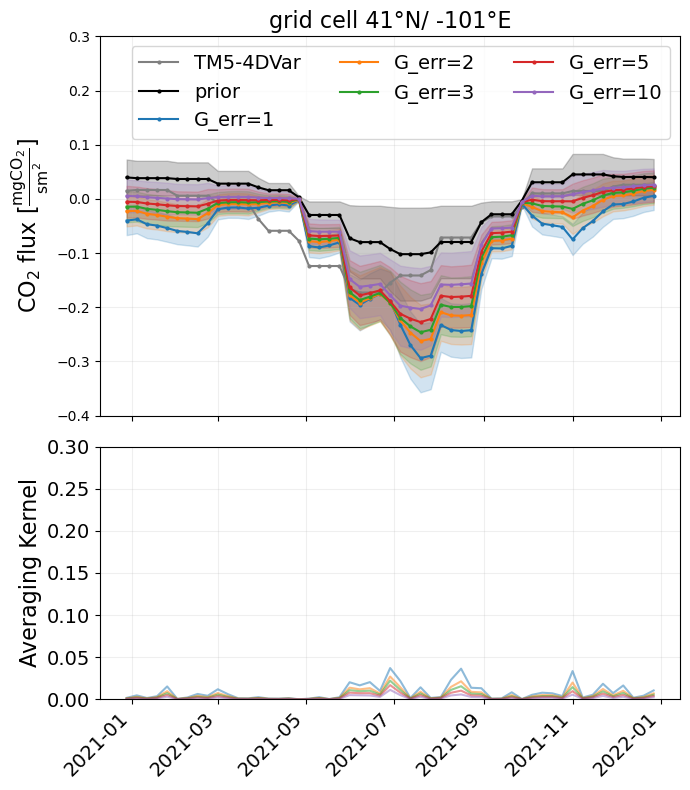

/tmp/ipykernel_3745970/1667248467.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


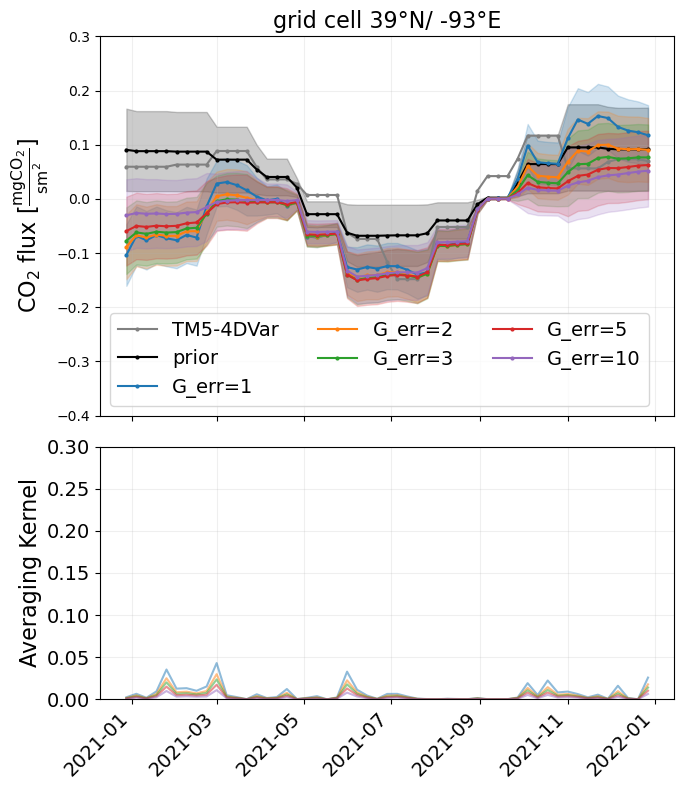

In [23]:
min,max=-0.4,0.3
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
lat_lon=[(41,-101),(39,-93)]

for lat,lon in lat_lon:
    fig,axs=plt.subplots(2,1,figsize=(7,8),gridspec_kw={'height_ratios': [3, 2]})
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    temp3=TM54DVar_posterior_flux.sel(latitude=lat,longitude=lon)
    temp3['total_flux']=temp3.total_flux*1e6
    axs[0].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar')
    k=0
    for g_err in gosat_err:
        temp=fluxes[g_err].sel(latitude=lat,longitude=lon)
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
        if k==0:
            axs[0].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
            axs[0].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2) 
        axs[0].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'G_err={g_err}')
        axs[0].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
        axs[1].plot(temp.time, temp.TM5_averaging_kernel_diag, color=default_colors[k], alpha=0.5)
        k+=1
    

    axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
    axs[0].legend(ncols=3,fontsize=14)
    axs[0].set_ylim(min,max)

    axs[0].tick_params(axis='x',labelbottom=False)
    axs[1].tick_params(axis='x', labelrotation=45,labelsize =14)
    plt.yticks(fontsize=14)
    axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')

    axs[0].grid(visible=True, which='major', axis='both', alpha=0.2)
    axs[1].grid(visible=True, which='major', axis='both', alpha=0.2)

    axs[1].set_ylabel('Averaging Kernel',fontsize=16)  # we already handled the x-label with ax1
    axs[1].tick_params(axis='y')
    axs[0].set_title(f"grid cell {lat}°N/ {lon}°E",fontsize=16)
    axs[1].set_ylim(0,0.3)
            #axs[i,j].tight_layout()
    plt.tight_layout()
    plt.savefig(f'{savefig}/only_gosat_err_inflation/girdbox_{lat}lat_{lon}lon.pdf',bbox_inches='tight',dpi=500)#,transparent=True)
    plt.show()


# only insitu

In [29]:
period='20201001-20220331'
analysis_start_date, analysis_end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
start_date, end_date =dt.date(2020,10,1), dt.date(2022,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/TM5/different_errors/'

In [30]:
path='inversions_new/TM5_only_insitu'
correlations=['with']
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

In [31]:
insitu_err=[1,2,3,5,10]
fluxes={}
gosat_data={}
tccon_data={}
insitu_data={}

In [32]:
for errors in insitu_err:
    print(errors)
    inversion_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/{errors}ppm_insitu_meas_err/'
    flux_path=f'{inversion_path}/20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc'
    fluxes[errors]=xr.open_dataset(flux_path)
    fluxes[errors]['time']=pd.to_datetime(fluxes[errors].time)
    fluxes[errors]=fluxes[errors].where((fluxes[errors].time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(fluxes[errors].time<=pd.to_datetime(analysis_end_date)),drop=True)

    gosat_data[errors]=xr.open_dataset(inversion_path+'gosat_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    gosat_data[errors]=gosat_data[errors].where((gosat_data[errors].release_time>=pd.to_datetime(analysis_start_date))&(gosat_data[errors].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    gosat_data[errors]=gosat_data[errors].where((gosat_data[errors].release_lat>analy_region_lat[0])&(gosat_data[errors].release_lat<analy_region_lat[1])&(gosat_data[errors].release_lon>analy_region_lon[0])&(gosat_data[errors].release_lon<analy_region_lon[1]),drop=True)

    tccon_data[errors]=xr.open_dataset(inversion_path+'TCCON_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    tccon_data[errors]=tccon_data[errors].where((tccon_data[errors].release_time>=pd.to_datetime(analysis_start_date))&(tccon_data[errors].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    tccon_data[errors]=tccon_data[errors].where((tccon_data[errors].release_lat>analy_region_lat[0])&(tccon_data[errors].release_lat<analy_region_lat[1])&(tccon_data[errors].release_lon>analy_region_lon[0])&(tccon_data[errors].release_lon<analy_region_lon[1]),drop=True)

    insitu_data[errors]=xr.open_dataset(inversion_path+'insitu_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    insitu_data[errors]=insitu_data[errors].where((insitu_data[errors].release_time>=pd.to_datetime(analysis_start_date))&(insitu_data[errors].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    insitu_data[errors]=insitu_data[errors].where((insitu_data[errors].release_lat>analy_region_lat[0])&(insitu_data[errors].release_lat<analy_region_lat[1])&(insitu_data[errors].release_lon>analy_region_lon[0])&(insitu_data[errors].release_lon<analy_region_lon[1]),drop=True)


1
2
3
5
10


<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:45: SyntaxWarning: invalid escape sequence '\o'
<>:45: SyntaxWarning: invalid escape sequence '\o'
<>:45: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:45: SyntaxWarning: invalid escape sequence '\o'
<>:45: SyntaxWarning: invalid escape sequence '\o'
<>:45: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_3745970/2774175875.py:18: SyntaxWarning: invalid escape sequence '\

insitu
IS_err=1, $\overline{d}=-0.05$,  $\overline{|d|}=1.88$, $\sigma=2.76$ N=1775
GOSAT
IS_err=1, $\overline{d}=0.08$,  $\overline{|d|}=1.9$, $\sigma=2.69$ N=5729
TCCON
IS_err=1, $\overline{d}=-1.1$,  $\overline{|d|}=1.75$, $\sigma=1.95$ N=973
insitu
IS_err=2, $\overline{d}=-0.07$,  $\overline{|d|}=2.02$, $\sigma=2.96$ N=1775
GOSAT
IS_err=2, $\overline{d}=0.04$,  $\overline{|d|}=1.9$, $\sigma=2.69$ N=5729
TCCON
IS_err=2, $\overline{d}=-1.12$,  $\overline{|d|}=1.77$, $\sigma=1.96$ N=973
insitu
IS_err=3, $\overline{d}=-0.08$,  $\overline{|d|}=2.09$, $\sigma=3.07$ N=1775
GOSAT
IS_err=3, $\overline{d}=0.02$,  $\overline{|d|}=1.9$, $\sigma=2.69$ N=5729
TCCON
IS_err=3, $\overline{d}=-1.14$,  $\overline{|d|}=1.78$, $\sigma=1.97$ N=973
insitu
IS_err=5, $\overline{d}=-0.1$,  $\overline{|d|}=2.17$, $\sigma=3.2$ N=1775
GOSAT
IS_err=5, $\overline{d}=-0.01$,  $\overline{|d|}=1.9$, $\sigma=2.69$ N=5729
TCCON
IS_err=5, $\overline{d}=-1.15$,  $\overline{|d|}=1.79$, $\sigma=1.97$ N=973
insitu
IS_err=

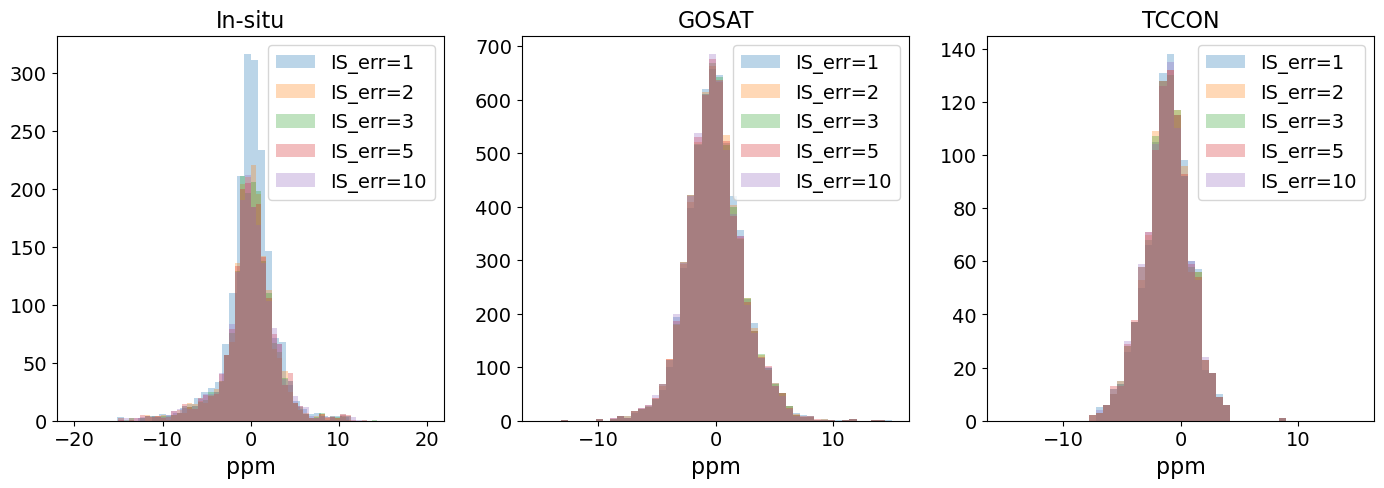

In [33]:
nbins=50
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for g_err in insitu_err:
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    temp=insitu_data[g_err]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=label=fr'{g_err}, $\overline{{d}}={d0}, \sigma={d_std}$'
    label=f'IS_err={g_err}'
    print('insitu')
    print(f'IS_err={g_err}, $\overline{{d}}={d0}$,  $\overline{{|d|}}={d_abs}$, $\sigma={d_std}$ N={len(temp.posterior_diff)}')
    axs[0].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[0].legend(fontsize=14)    
    axs[0].set_xlabel('ppm',fontsize=16)
    axs[0].set_title(title[0],fontsize=16)
    axs[0].tick_params(labelsize =14)

    max_min=(-15,15)
    temp=gosat_data[g_err]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    print('GOSAT')
    print(f'IS_err={g_err}, $\overline{{d}}={d0}$,  $\overline{{|d|}}={d_abs}$, $\sigma={d_std}$ N={len(temp.posterior_diff)}')
    axs[1].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[1].legend(fontsize=14)    
    axs[1].set_xlabel('ppm',fontsize=16)
    axs[1].set_title(title[1],fontsize=16)
    axs[1].tick_params(labelsize =14)

    
    max_min=(-15,15)
    temp=tccon_data[g_err]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    print('TCCON')
    print(f'IS_err={g_err}, $\overline{{d}}={d0}$,  $\overline{{|d|}}={d_abs}$, $\sigma={d_std}$ N={len(temp.posterior_diff)}')
    axs[2].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[2].legend(fontsize=14)    
    axs[2].set_xlabel('ppm',fontsize=16)
    axs[2].set_title(title[2],fontsize=16)
    axs[2].tick_params(labelsize =14)
plt.savefig(f'{savefig}/histogramm_diff_insitu_err_with_inflation.pdf',bbox_inches='tight',dpi=500)

<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_885105/1527235955.py:31: SyntaxWarning: invalid escape sequence '\m'
  axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')


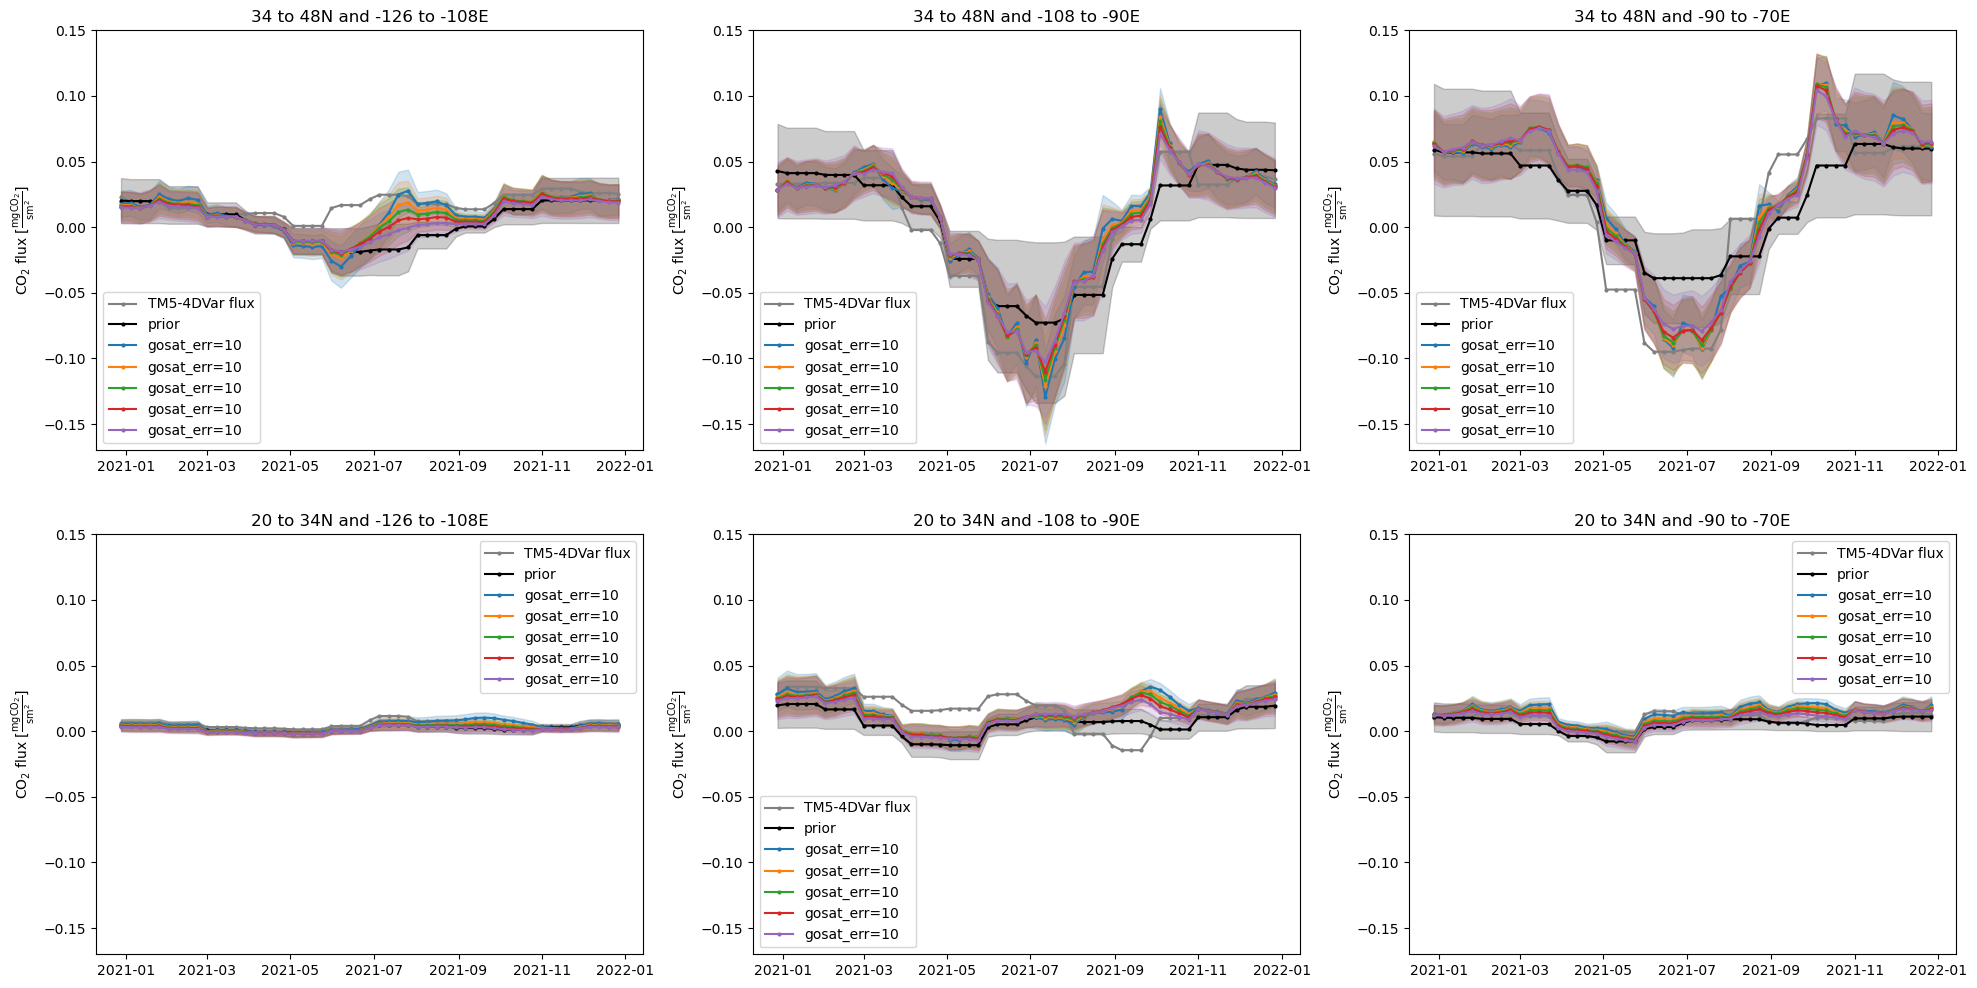

In [30]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        
        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')

        k=0
        for err in insitu_err:
            temp=fluxes[err]
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            if k==0:
                axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
                axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2)  
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'gosat_err={g_err}')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')
        axs[i,j].legend()
        axs[i,j].set_ylim(-0.17,0.15)
        #axs[i,j].xticks(rotation=45)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        #axs[i,j].tight_layout()
plt.savefig(f'{savefig}/regional_fluxes_diff_insitu.png',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

In [31]:
prior_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/2ppm_insitu_meas_err//{period}_{BG_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

colors=['orange','green']
marker=['x','x']
k=0
for errors in insitu_err:
    datasets_dir.append(f'{path}/2x2/with_correlation/footprint_spec001_mr/{errors}ppm_insitu_meas_err/{period}_{BG_ds}_bg.nc')
    labels.append(f'posterior i_err={errors}')
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')

print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'different insitu errors', start_date, end_date,savefig+'different_insitu_err_'+'2x2.png')


['TM5_prior_flux', 'total_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux']
['prior_uncertainty', False, 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std']
['orange', 'green', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
['x', 'x', 'o', 'o', 'o', 'o', 'o']
saved to: figures_2/TM5/different_errors/different_insitu_err_2x2.png


<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3745970/2826198881.py:27: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
/tmp/ipykernel_3745970/2826198881.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


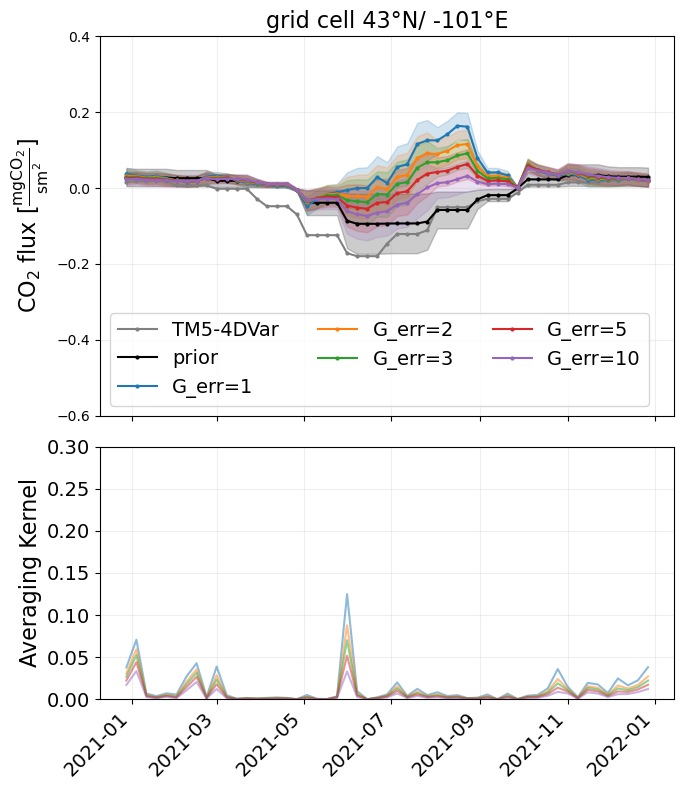

/tmp/ipykernel_3745970/2826198881.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


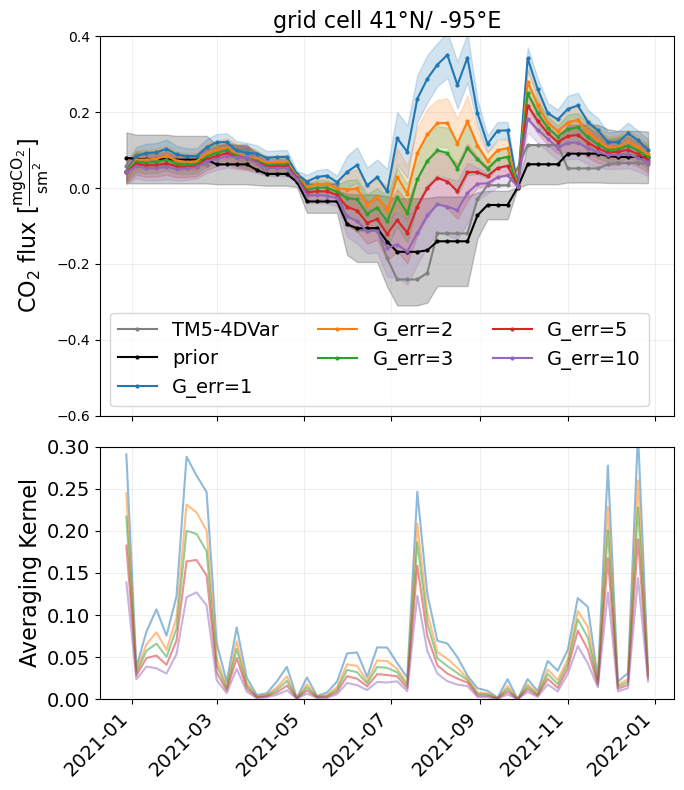

/tmp/ipykernel_3745970/2826198881.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


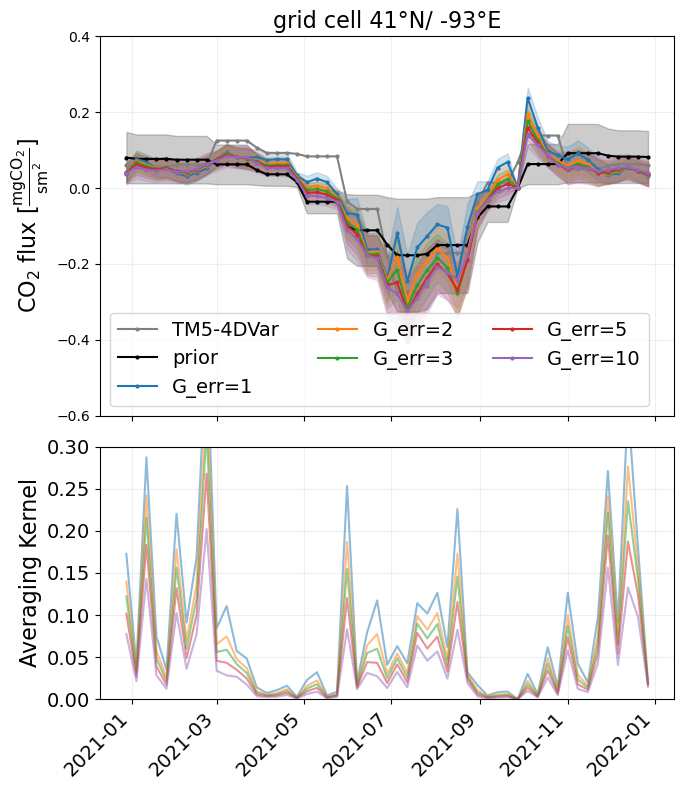

/tmp/ipykernel_3745970/2826198881.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


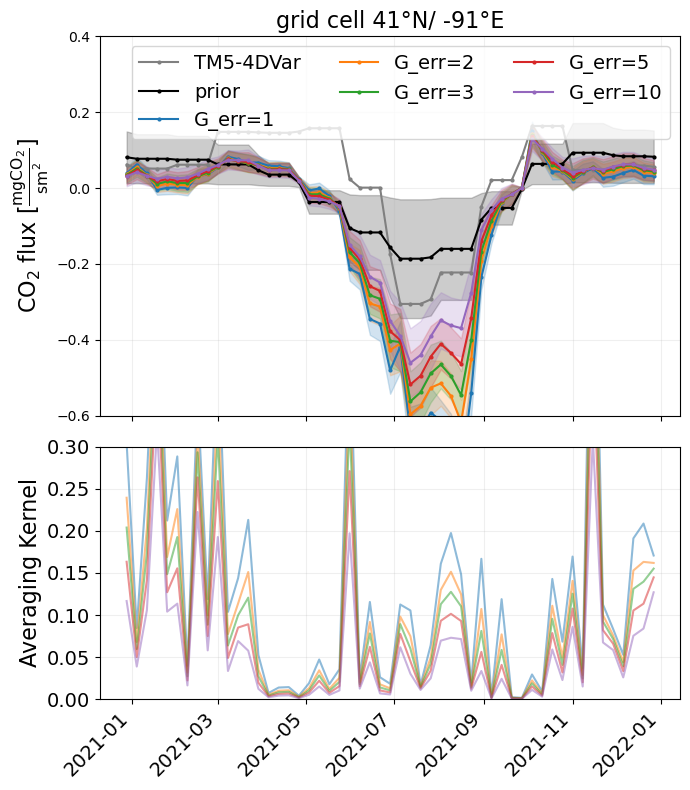

In [34]:
min,max=-0.6,0.4
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
lat_lon=[(43,-101),(41,-95),(41,-93),(41,-91)]

for lat,lon in lat_lon:
    fig,axs=plt.subplots(2,1,figsize=(7,8),gridspec_kw={'height_ratios': [3, 2]})
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    temp3=TM54DVar_posterior_flux.sel(latitude=lat,longitude=lon)
    temp3['total_flux']=temp3.total_flux*1e6
    axs[0].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar')
    k=0
    for err in insitu_err:
        temp=fluxes[err].sel(latitude=lat,longitude=lon)
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
        if k==0:
            axs[0].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
            axs[0].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2) 
        axs[0].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'G_err={err}')
        axs[0].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
        axs[1].plot(temp.time, temp.TM5_averaging_kernel_diag, color=default_colors[k], alpha=0.5)
        k+=1
    

    axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
    axs[0].legend(ncols=3,fontsize=14)
    axs[0].set_ylim(min,max)

    axs[0].tick_params(axis='x',labelbottom=False)
    axs[1].tick_params(axis='x', labelrotation=45,labelsize =14)
    plt.yticks(fontsize=14)
    axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')

    axs[0].grid(visible=True, which='major', axis='both', alpha=0.2)
    axs[1].grid(visible=True, which='major', axis='both', alpha=0.2)

    axs[1].set_ylabel('Averaging Kernel',fontsize=16)  # we already handled the x-label with ax1
    axs[1].tick_params(axis='y')
    axs[0].set_title(f"grid cell {lat}°N/ {lon}°E",fontsize=16)
    axs[1].set_ylim(0,0.3)
            #axs[i,j].tight_layout()
    plt.tight_layout()
    plt.savefig(f'{savefig}/only_insitu_err/girdbox_{lat}lat_{lon}lon.pdf',bbox_inches='tight',dpi=500)#,transparent=True)
    plt.show()


# comparing only insitu (IS), only gosat (G), both insitu and gosat (IS+G)

In [7]:
path='inversions_new/'
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

In [8]:
fluxes={}
gosat_data={}
tccon_data={}
insitu_data={}

In [9]:
inversions=['IS','G','IS+G']
paths=[path+'/TM5_only_insitu/',path+'/TM5_only_gosat/',path+'TM5_correlations']
i_err=[3,'NaN',3]
savefig='figures_2/TM5/different_errors/i_err3/'
g_err=['NaN',2,2]
for k,inversion in enumerate(inversions):
    print(inversion)
    inversion_path=f'{paths[k]}/2x2/with_correlation/footprint_spec001_mr/'
    if 'G' in inversion:
        inversion_path+=f'/{g_err[k]}ppm_gosat_meas_err/'
    if 'IS' in inversion:
        inversion_path+=f'/{i_err[k]}ppm_insitu_meas_err/'
    flux_path=f'{inversion_path}/20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc'
    fluxes[inversion]=xr.open_dataset(flux_path)
    fluxes[inversion]['time']=pd.to_datetime(fluxes[inversion].time)
    fluxes[inversion]=fluxes[inversion].where((fluxes[inversion].time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(fluxes[inversion].time<=pd.to_datetime(analysis_end_date)),drop=True)
    
    gosat_data[inversion]=xr.open_dataset(inversion_path+'gosat_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    gosat_data[inversion]=gosat_data[inversion].where((gosat_data[inversion].release_time>=pd.to_datetime(analysis_start_date))&(gosat_data[inversion].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    gosat_data[inversion]=gosat_data[inversion].where((gosat_data[inversion].release_lat>analy_region_lat[0])&(gosat_data[inversion].release_lat<analy_region_lat[1])&(gosat_data[inversion].release_lon>analy_region_lon[0])&(gosat_data[inversion].release_lon<analy_region_lon[1]),drop=True)

    tccon_data[inversion]=xr.open_dataset(inversion_path+'TCCON_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    tccon_data[inversion]=tccon_data[inversion].where((tccon_data[inversion].release_time>=pd.to_datetime(analysis_start_date))&(tccon_data[inversion].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    tccon_data[inversion]=tccon_data[inversion].where((tccon_data[inversion].release_lat>analy_region_lat[0])&(tccon_data[inversion].release_lat<analy_region_lat[1])&(tccon_data[inversion].release_lon>analy_region_lon[0])&(tccon_data[inversion].release_lon<analy_region_lon[1]),drop=True)

    insitu_data[inversion]=xr.open_dataset(inversion_path+'insitu_data_2x2_20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
    insitu_data[inversion]=insitu_data[inversion].where((insitu_data[inversion].release_time>=pd.to_datetime(analysis_start_date))&(insitu_data[inversion].release_time<=pd.to_datetime(analysis_end_date)),drop=True)
    insitu_data[inversion]=insitu_data[inversion].where((insitu_data[inversion].release_lat>analy_region_lat[0])&(insitu_data[inversion].release_lat<analy_region_lat[1])&(insitu_data[inversion].release_lon>analy_region_lon[0])&(insitu_data[inversion].release_lon<analy_region_lon[1]),drop=True)




IS
G
IS+G


insitu IS & $\overline{d}=-0.08$ & $\overline{|d|}=2.09$ & $\sigma=3.07$
GOSAT IS, $\overline{d}=0.02 $& $\overline{|d|}=1.9$ & $\sigma=2.69$
TCCON IS, $\overline{d}=-1.14$ & $\overline{|d|}=1.78$ & $\sigma=1.97$
insitu G & $\overline{d}=-2.82$ & $\overline{|d|}=5.27$ & $\sigma=7.2$
GOSAT G, $\overline{d}=-0.05 $& $\overline{|d|}=1.7$ & $\sigma=2.47$
TCCON G, $\overline{d}=-1.01$ & $\overline{|d|}=1.67$ & $\sigma=1.86$
insitu IS+G & $\overline{d}=-0.08$ & $\overline{|d|}=2.14$ & $\sigma=3.13$
GOSAT IS+G, $\overline{d}=0.12 $& $\overline{|d|}=1.78$ & $\sigma=2.56$
TCCON IS+G, $\overline{d}=-0.98$ & $\overline{|d|}=1.65$ & $\sigma=1.85$


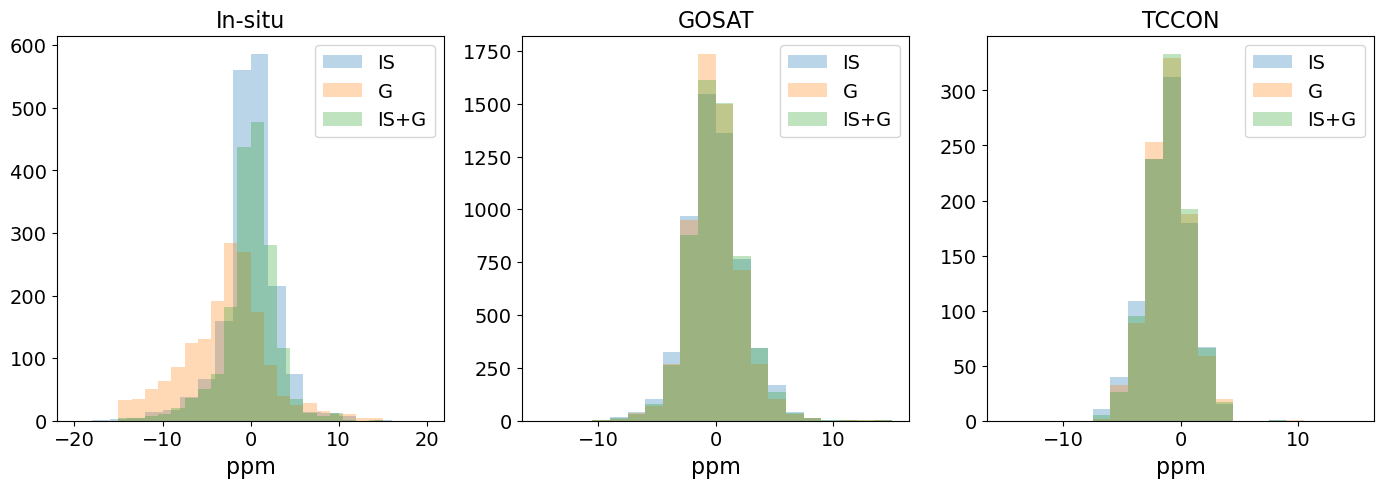

In [13]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for inversion in inversions:
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    temp=insitu_data[inversion]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{inversion} & $\overline{{d}}={d0}$ & $\overline{{|d|}}={d_abs}$ & $\sigma={d_std}$'
    print(f'insitu {label}')
    axs[0].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=inversion)
    axs[0].legend(fontsize=14)    
    axs[0].set_xlabel('ppm',fontsize=16)
    axs[0].set_title(title[0],fontsize=16)
    axs[0].tick_params(labelsize =14)

    max_min=(-15,15)
    temp=gosat_data[inversion]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{inversion}, $\overline{{d}}={d0} $& $\overline{{|d|}}={d_abs}$ & $\sigma={d_std}$'
    print(f'GOSAT {label}')
    axs[1].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=inversion)
    axs[1].legend(fontsize=14)    
    axs[1].set_xlabel('ppm',fontsize=16)
    axs[1].set_title(title[1],fontsize=16)
    axs[1].tick_params(labelsize =14)

    
    max_min=(-15,15)
    temp=tccon_data[inversion]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=label=fr'{inversion}, $\overline{{d}}={d0}$ & $\overline{{|d|}}={d_abs}$ & $\sigma={d_std}$'
    print(f'TCCON {label}')
    axs[2].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=inversion)
    axs[2].legend(fontsize=14)    
    axs[2].set_xlabel('ppm',fontsize=16)
    axs[2].set_title(title[2],fontsize=16)
    axs[2].tick_params(labelsize =14)
plt.savefig(f'{savefig}/histogramm_comparing_onlys.pdf',dpi=500)

/tmp/ipykernel_670166/1744192808.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_670166/1744192808.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_670166/1744192808.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


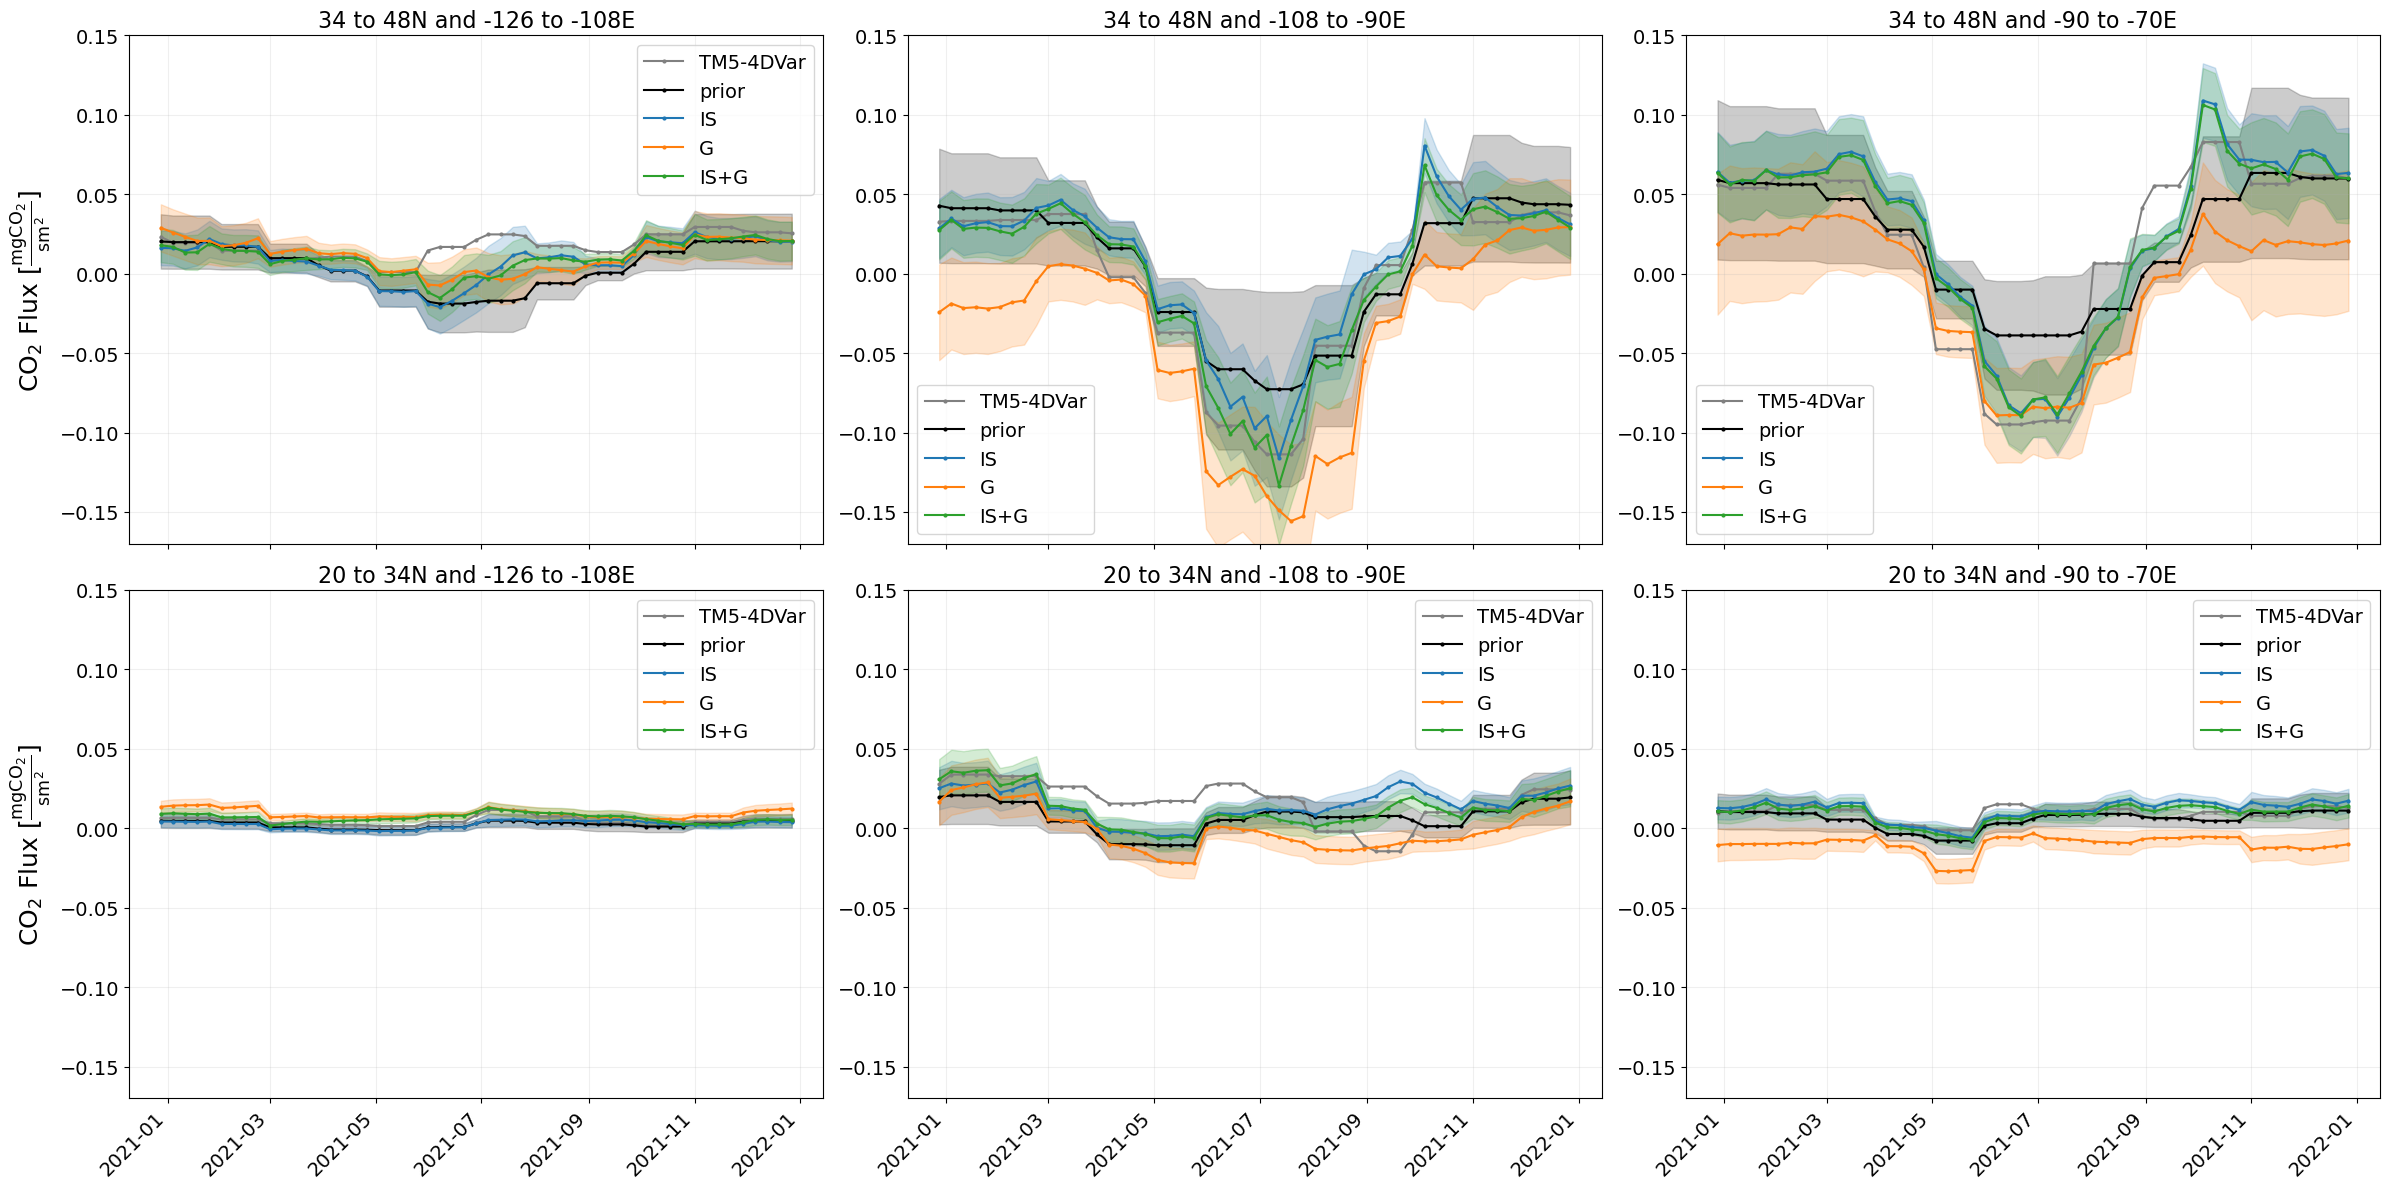

In [13]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        
        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar')

        k=0
        for inversion in inversions:
            temp=fluxes[inversion]
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            if k==0:
                axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
                axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2)  
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{inversion}')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(-0.17,0.15)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.tight_layout()
plt.savefig(f'{savefig}/regional_fluxes_comparing_onlys.pdf',bbox_inches='tight',dpi=500)#,transparent=True)
plt.show()
#plt.close()

In [11]:
prior_path=f'inversions_new/TM5_only_insitu/2x2/with_correlation/footprint_spec001_mr/2ppm_insitu_meas_err//{period}_{BG_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

colors=['black','grey']
marker=['x','x']
k=0
inversions=['IS','G','IS+G']
path='inversions_new/'
paths=[path+'/TM5_only_insitu/',path+'/TM5_only_gosat/',path+'/TM5_correlations/']
i_err=[5,'NaN',5]
g_err=['NaN',2,2]
for k,inversion in enumerate(inversions):
    inversion_path=f'{paths[k]}/2x2/with_correlation/footprint_spec001_mr/'
    if 'G' in inversion:
        inversion_path+=f'/{g_err[k]}ppm_gosat_meas_err/'
    if 'IS' in inversion:
        inversion_path+=f'/{i_err[k]}ppm_insitu_meas_err/'
    inversion_path+=f'{period}_{BG_ds}_bg.nc'
    datasets_dir.append(inversion_path)
    labels.append(inversion)
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')

print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'comparison IS, G, IS+G', start_date, end_date,savefig+'comparison_onlys'+'2x2.png')


['TM5_prior_flux', 'total_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux']
['prior_uncertainty', False, 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std']
['black', 'grey', '#1f77b4', '#ff7f0e', '#2ca02c']
['x', 'x', 'o', 'o', 'o']
saved to: figures_2/TM5/different_errors/i_err5/comparison_onlys2x2.png


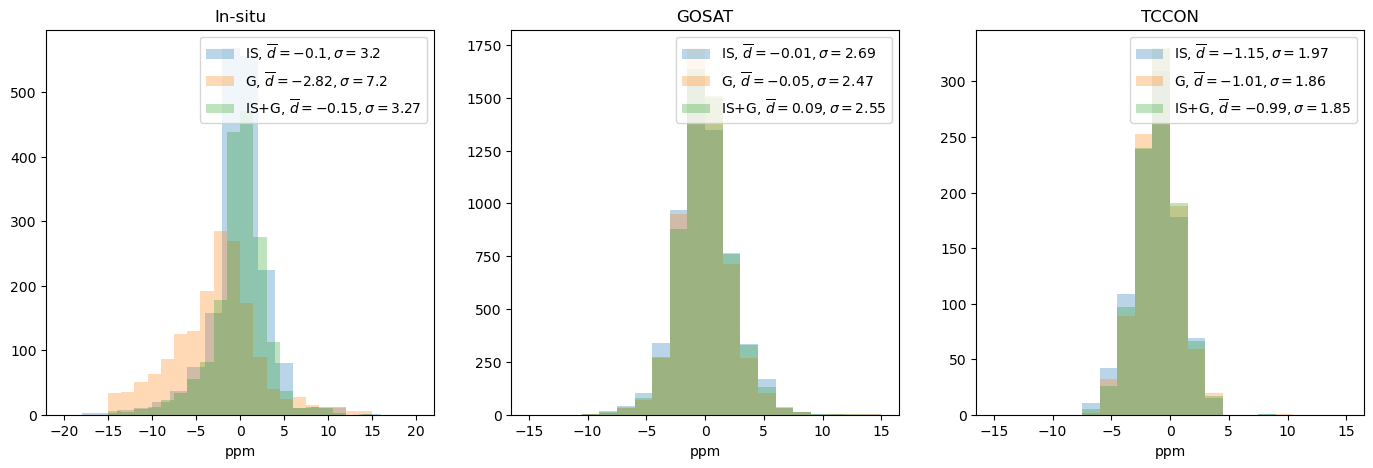

In [140]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for inversion in inversions:
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    temp=insitu_data[inversion]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=f'{inversion}'
    print('insitu')
    print(f'{inversion}, $\overline{{d}}={d0}$,  $\overline{{|d|}}={d_abs}$, $\sigma={d_std}$ N={len(temp.posterior_diff)}')
    axs[0].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[0].legend()
    axs[0].set_xlabel('ppm')
    axs[0].set_title(title[0])

    max_min=(-15,15)
    temp=gosat_data[inversion]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=f'{inversion}'
    print('insitu')
    print(f'{inversion}, $\overline{{d}}={d0}$,  $\overline{{|d|}}={d_abs}$, $\sigma={d_std}$ N={len(temp.posterior_diff)}')
    axs[1].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[1].legend()
    axs[1].set_xlabel('ppm')
    axs[1].set_title(title[1])

    
    max_min=(-15,15)
    temp=tccon_data[inversion]
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=f'{inversion}'
    print('insitu')
    print(f'{inversion}, $\overline{{d}}={d0}$,  $\overline{{|d|}}={d_abs}$, $\sigma={d_std}$ N={len(temp.posterior_diff)}')
    axs[2].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[2].legend()
    axs[2].set_xlabel('ppm')
    axs[2].set_title(title[2])

plt.savefig(f'{savefig}/histogramm_comparing_onlys.png')

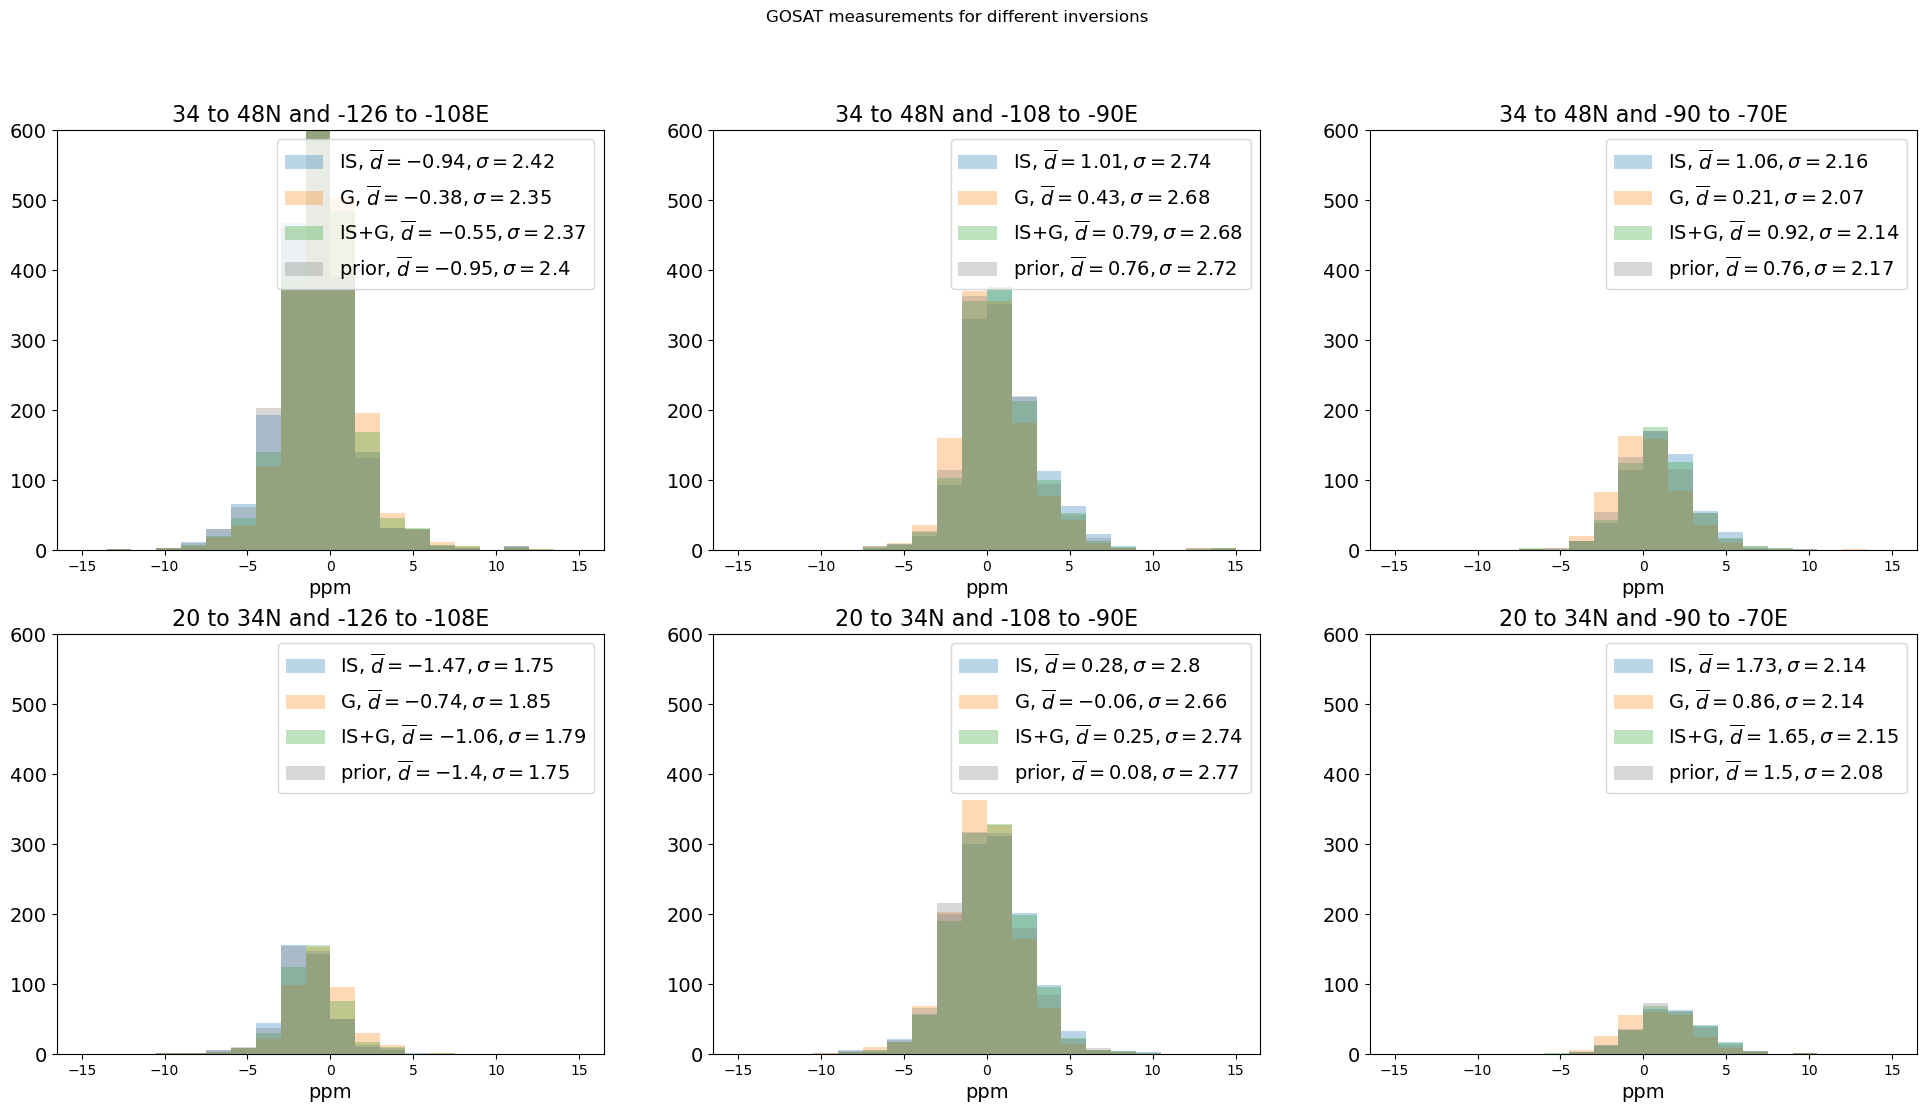

In [69]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
nbins=20
max_min=(-20,20)
title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        for k,inversion in enumerate(['IS','G','IS+G','prior']):    #'prior']):
            max_min=(-15,15)
            if inversion=='prior':
                temp=gosat_data['IS']
            else:
                temp=gosat_data[inversion]
            temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
            if inversion=='prior':
                d0=np.round(np.mean(temp.prior_diff).compute().item(),2)
                d_abs=np.round(np.mean(np.abs(temp.prior_diff)).compute().item(),2)
                d_std=np.round(np.std(temp.prior_diff).compute().item(),2)
                label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
                axs[i,j].hist(temp.prior_diff,alpha=0.3,color='gray', bins=nbins, range=max_min, label=label)
            else:
                d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
                d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
                d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
                label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
                axs[i,j].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
        axs[i,j].set_xlabel('ppm',fontsize=14)
        axs[i,j].legend(fontsize=14)
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
        axs[i,j].set_ylim(0,600)
        #axs[i,j].tight_layout()
fig.suptitle('GOSAT measurements for different inversions')
plt.savefig(f'{savefig}/regional_GOSAT_hist_comparing_onlys+both.png',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


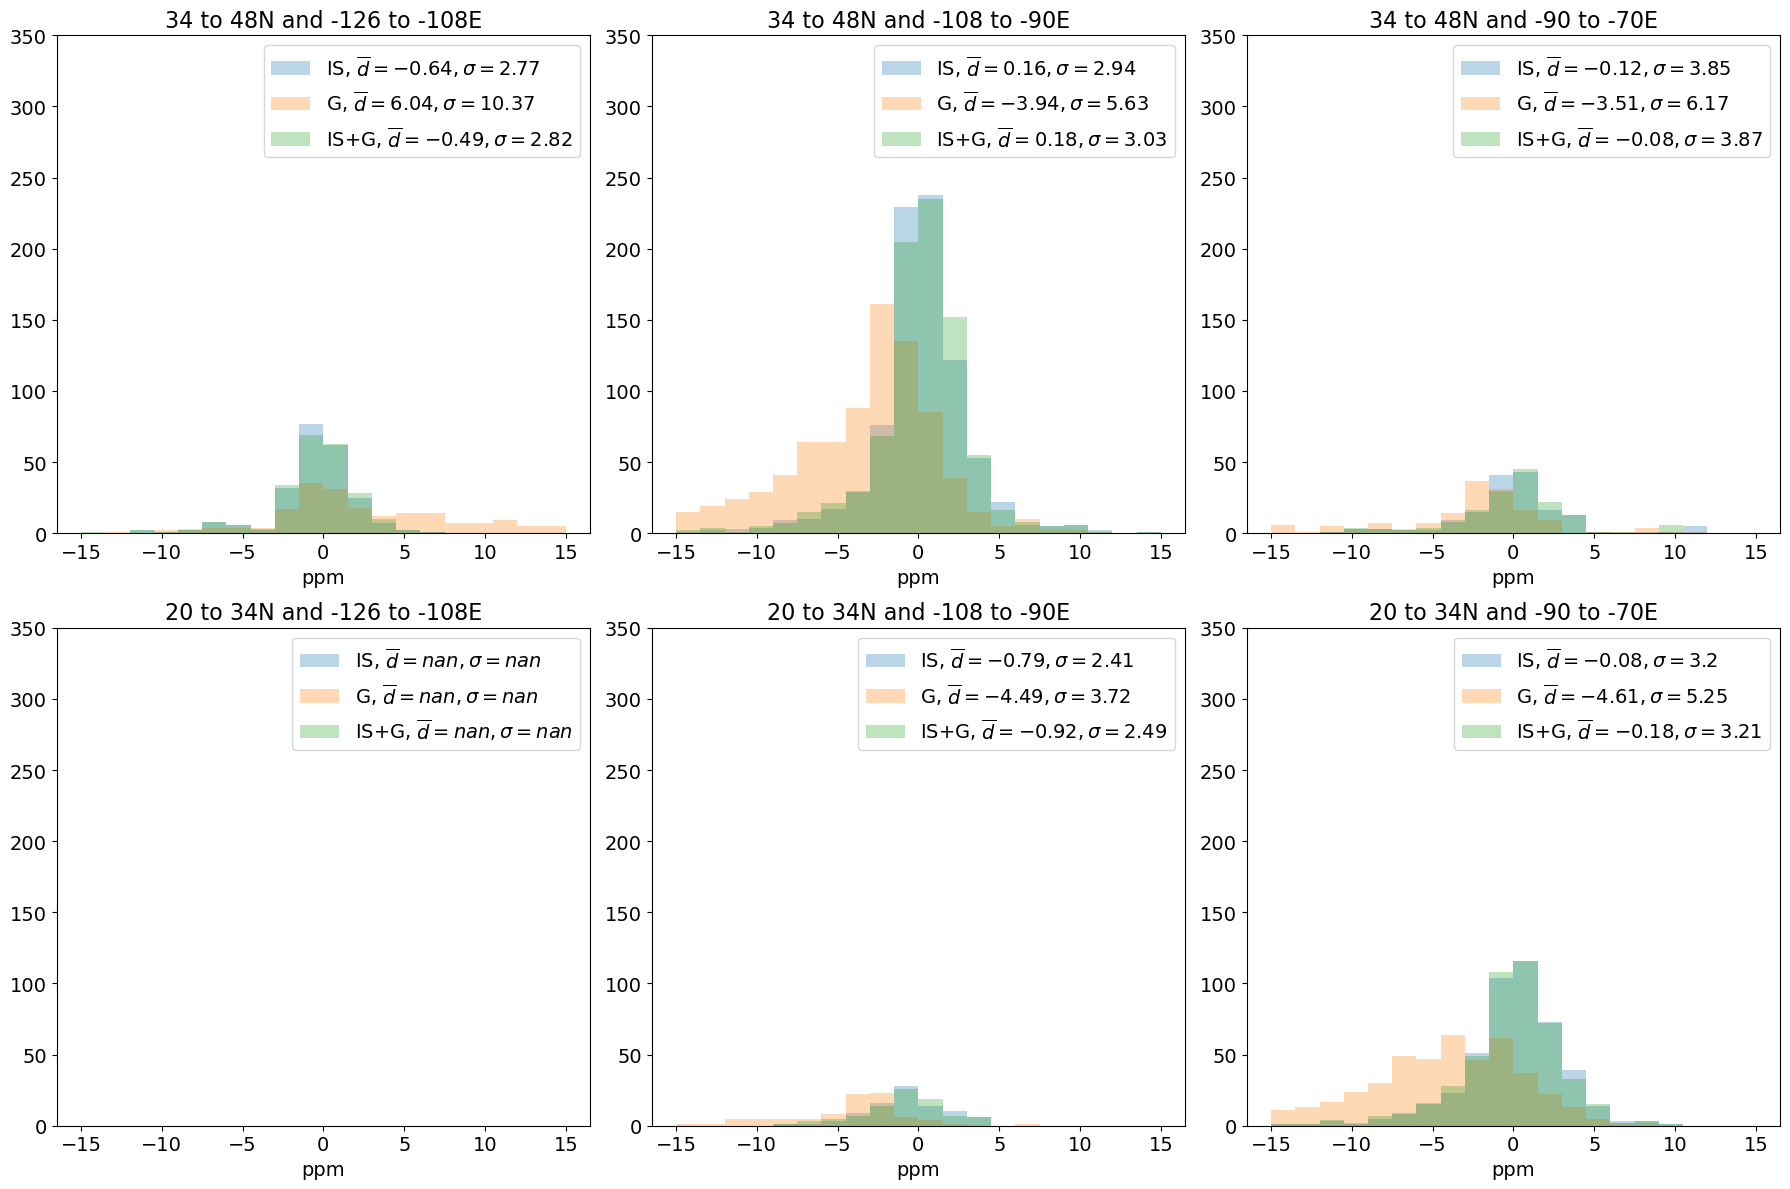

In [27]:
fig,axs=plt.subplots(2,3,figsize=(18,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
nbins=20
max_min=(-20,20)
title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        for k,inversion in enumerate(['IS','G','IS+G',]): #'prior'
            if False: #g_err==1 or g_err==2 or g_err==3:
                continue
            max_min=(-15,15)
            if inversion=='prior':
                temp=insitu_data['IS']
            else:
                temp=insitu_data[inversion]
            temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
            if inversion=='prior':
                d0=np.round(np.mean(temp.prior_diff).compute().item(),2)
                d_abs=np.round(np.mean(np.abs(temp.prior_diff)).compute().item(),2)
                d_std=np.round(np.std(temp.prior_diff).compute().item(),2)
                label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
                axs[i,j].hist(temp.prior_diff,alpha=0.3,color='gray', bins=nbins, range=max_min, label=label)
            else:
                d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
                d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
                d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
                label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
                axs[i,j].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
        axs[i,j].set_xlabel('ppm',fontsize=14)
        axs[i,j].legend(fontsize=14)
        axs[i,j].tick_params( labelsize =14)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
        axs[i,j].set_ylim(0,350)
        #axs[i,j].tight_layout()
#fig.suptitle('in-situ measurements for different inversions',fontsize=16)
plt.tight_layout()
plt.savefig(f'{savefig}/regional_IS_hist_comparing_onlys+both.pdf',bbox_inches='tight',dpi=500)#,transparent=True)
plt.show()
#plt.close()

In [43]:
seasons={'winter': [12,1,2],
         'spring': [3,4,5],
         'summer': [6,7,8],
         'autumn': [9,10,11]}

In [25]:
def plot_averaging_kernel(data,label,ax,vmax=0.5, cmap='Reds'):
    plot=data.plot(ax=ax, cmap= cmap, vmin=0, vmax=vmax,rasterized=True, cbar_kwargs={'location':'bottom', 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(20)
    plot.colorbar.ax.tick_params(labelsize=17)
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 16}
    gl.ylabel_style = {'size': 16}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')
# Define a custom normalization to emphasize positive values
class AsymmetricNorm(mcolors.Normalize):
    def __init__(self, vmin, vmax, midpoint=0, clip=False):
        self.midpoint = midpoint
        super().__init__(vmin, vmax, clip)

    def __call__(self, value, clip=None):
        # Map negative values to [0, 0.5], positive to [0.5,1]
        result, is_scalar = self.process_value(value)
        vmin, vmax, m = self.vmin, self.vmax, self.midpoint
        rescaled = np.zeros_like(result)
        # Negative values
        neg_mask = result < m
        rescaled[neg_mask] = 0.5 * (result[neg_mask] - vmin) / (m - vmin)
        # Positive values
        pos_mask = result >= m
        rescaled[pos_mask] = 0.5 + 0.5 * (result[pos_mask] - m) / (vmax - m)
        if is_scalar:
            return rescaled[0]
        return rescaled

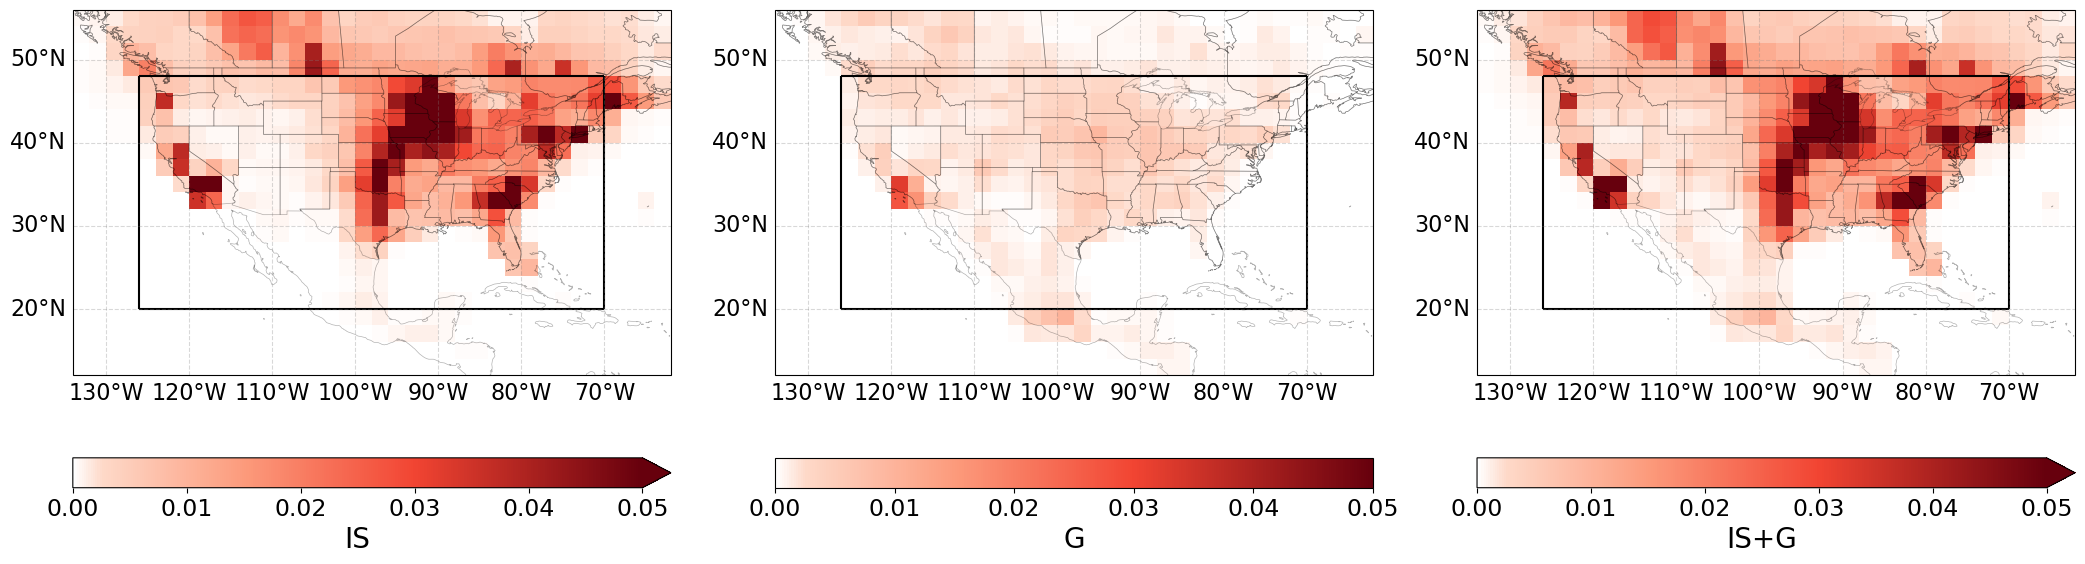

In [26]:
k=0
cmap= LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

#for week in inversion.data[inversion.correlations[0]].fluxes.time.values:
fig,axs=plt.subplots(1,3,figsize=(21,6), subplot_kw={'projection': ccrs.PlateCarree()})
#fig.suptitle("mean of diagonal of Averaging Kernel", fontsize=16)#, fontweight='bold')
#fig.text(0.5, 0.92, f"Week of the {str(np.datetime64(week,'D'))}", ha='center', fontsize=12, style='italic')
fig.subplots_adjust(right=0.85)
for i,inversion in enumerate(inversions):
    temp=(fluxes[inversion].TM5_averaging_kernel_diag).mean('time')
    plot_averaging_kernel(temp,inversion,axs[i],vmax=0.05, cmap=cmap)
plt.tight_layout()
plt.savefig(f'{savefig}/averaging_kernel_onlys.pdf')
plt.show()


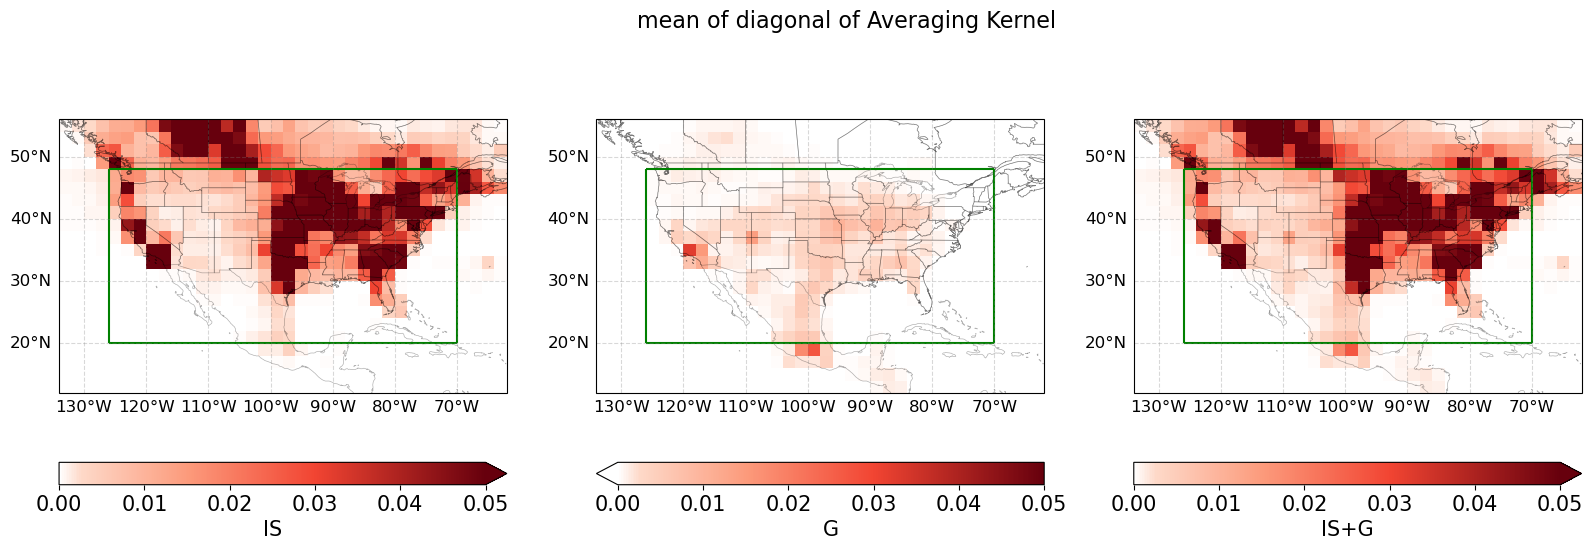

In [53]:
k=0
cmap= LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

#for week in inversion.data[inversion.correlations[0]].fluxes.time.values:
fig,axs=plt.subplots(1,3,figsize=(21,6), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("mean of diagonal of Averaging Kernel", fontsize=16)#, fontweight='bold')
#fig.text(0.5, 0.92, f"Week of the {str(np.datetime64(week,'D'))}", ha='center', fontsize=12, style='italic')
fig.subplots_adjust(right=0.85)
for i,inversion in enumerate(inversions):
    temp=(fluxes[inversion].TM5_averaging_kernel_diag)
    temp=temp.where((temp.time.dt.month==12)|(temp.time.dt.month==1)|(temp.time.dt.month==2), drop=True)
    plot_averaging_kernel(temp.mean('time'),inversion,axs[i],vmax=0.05, cmap=cmap)
plt.savefig(f'{savefig}/averaging_kernel_onlys_winter.png')
plt.show()

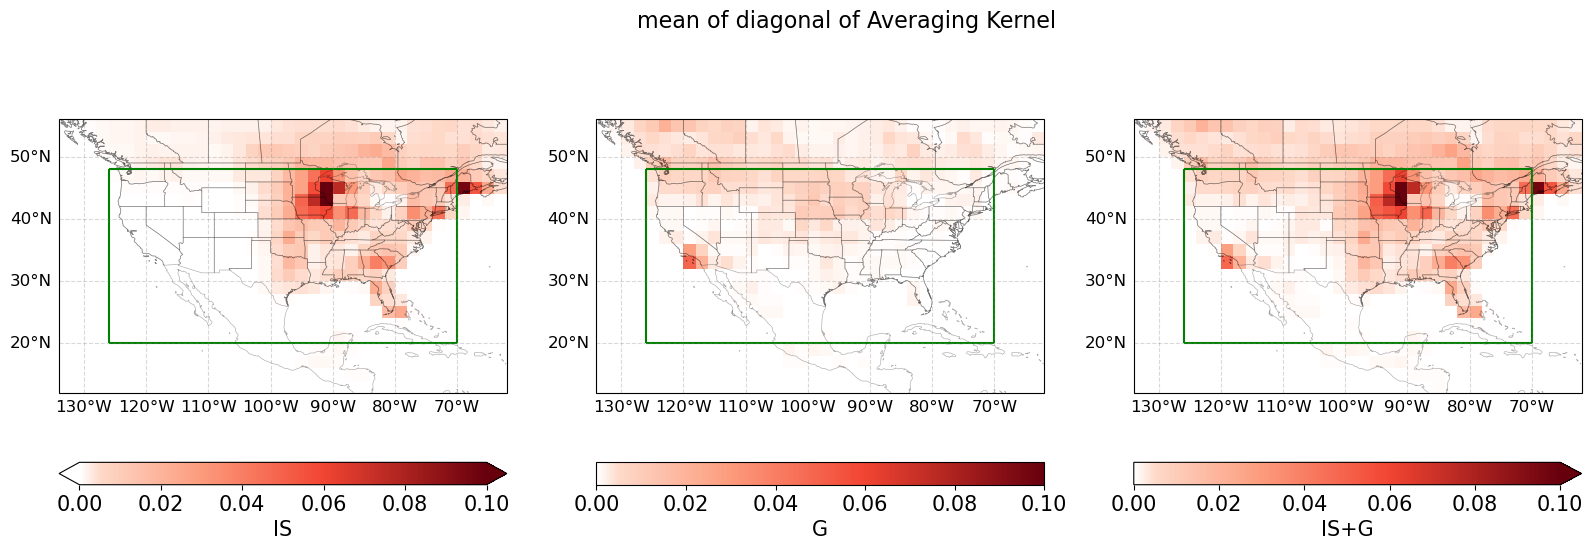

In [55]:
k=0
cmap= LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

#for week in inversion.data[inversion.correlations[0]].fluxes.time.values:
fig,axs=plt.subplots(1,3,figsize=(21,6), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("mean of diagonal of Averaging Kernel", fontsize=16)#, fontweight='bold')
#fig.text(0.5, 0.92, f"Week of the {str(np.datetime64(week,'D'))}", ha='center', fontsize=12, style='italic')
fig.subplots_adjust(right=0.85)
for i,inversion in enumerate(inversions):
    temp=(fluxes[inversion].TM5_averaging_kernel_diag)
    temp=temp.where((temp.time.dt.month==6)|(temp.time.dt.month==7)|(temp.time.dt.month==8), drop=True)
    plot_averaging_kernel(temp.mean('time'),inversion,axs[i],vmax=0.1, cmap=cmap)
plt.savefig(f'{savefig}/averaging_kernel_onlys_summer.png')
plt.show()

In [66]:
def plot_map(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(16)
    plot.colorbar.ax.tick_params(labelsize=16)
           
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 15}
    gl.ylabel_style = {'size': 15}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

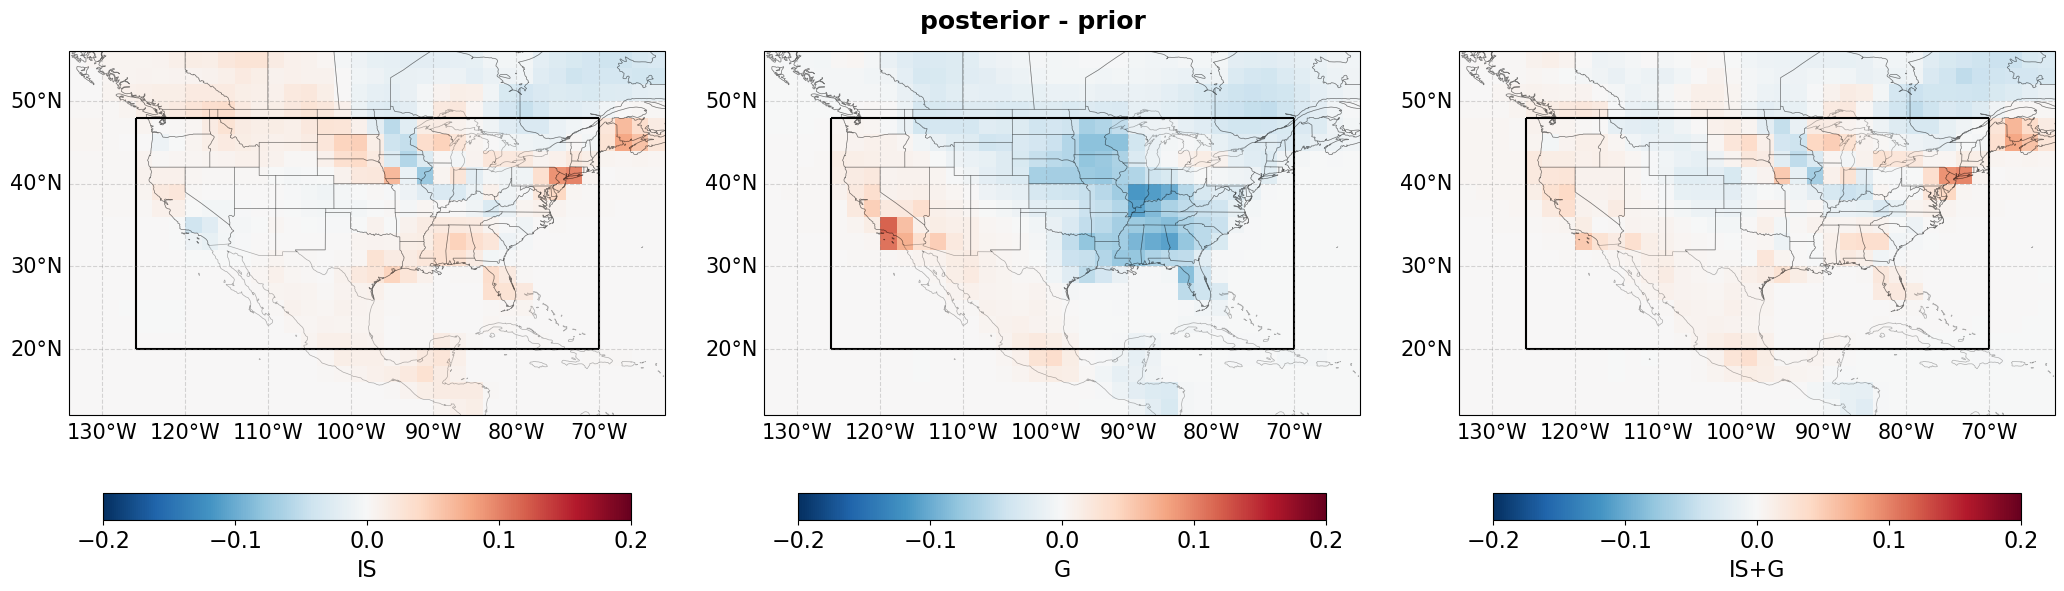

In [67]:
k=0
cmap= LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

fig,axs=plt.subplots(1,3,figsize=(21,6), subplot_kw={'projection': ccrs.PlateCarree()})
fig.suptitle("posterior - prior", fontsize=18, fontweight='bold')
fig.subplots_adjust(right=0.85)
for i,inversion in enumerate(inversions):
    temp=(fluxes[inversion].TM5_posterior_flux-fluxes[inversion].TM5_prior_flux)*1e6
    plot_map(temp.mean('time'),'$\mathrm{\\frac{mgCO_2}{s m^2}}$',axs[i],vmin=-0.2,vmax=0.2)
    axs[i].set_title(inversion)
plt.tight_layout()
plt.savefig(f'{savefig}/posterior-prior_onlys.png',bbox_inches='tight',dpi=500)
plt.show()

In [88]:
#for week in inversion.data[inversion.correlations[0]].fluxes.time.values:
k=0
cmap= LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

for week in fluxes[inversions[0]].time.values:
    fig,axs=plt.subplots(1,3,figsize=(21,6), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle("posterior - prior", fontsize=18, fontweight='bold',y=1.04)
    fig.text(0.5,0.97, f"Week of the {str(np.datetime64(week,'D'))}", ha='center', fontsize=14, style='italic')
    fig.subplots_adjust(right=0.85)
    for i,inversion in enumerate(inversions):
        temp=(fluxes[inversion].TM5_posterior_flux-fluxes[inversion].TM5_prior_flux)*1e6
        temp=temp.where(temp.time==week, drop=True)     
        plot_map(temp.mean('time'),'$\mathrm{\\frac{mgCO_2}{s m^2}}$',axs[i],vmin=-0.2,vmax=0.2)
        axs[i].set_title(inversion, fontsize=16)
    plt.tight_layout()
    plt.savefig(f'{savefig}/posterior-prior/posterior-prior_onlys_{k:03d}.png',bbox_inches='tight',dpi=500)
    plt.close()
    k+=1


<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1093478/2513158336.py:13: SyntaxWarning: invalid escape sequence '\m'
  plot_map(temp.mean('time'),'$\mathrm{\\frac{mgCO_2}{s m^2}}$',axs[i],vmin=-0.2,vmax=0.2)


<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1093478/1889824289.py:13: SyntaxWarning: invalid escape sequence '\m'
  plot_map(temp.mean('time'),'$\mathrm{\\frac{mgCO_2}{s m^2}}$',axs[i],vmin=-0.2,vmax=0.2)


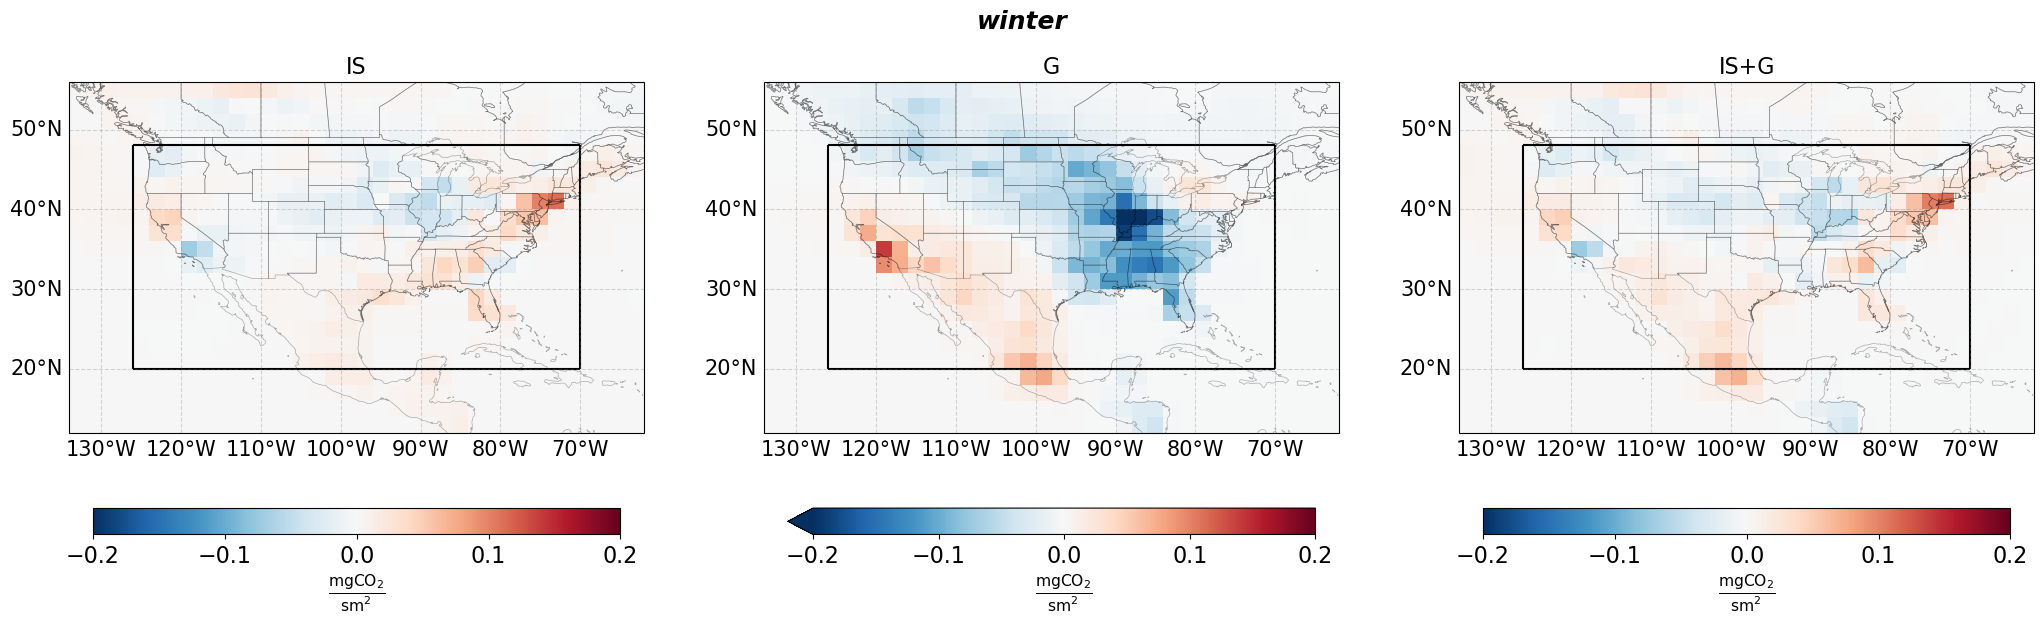

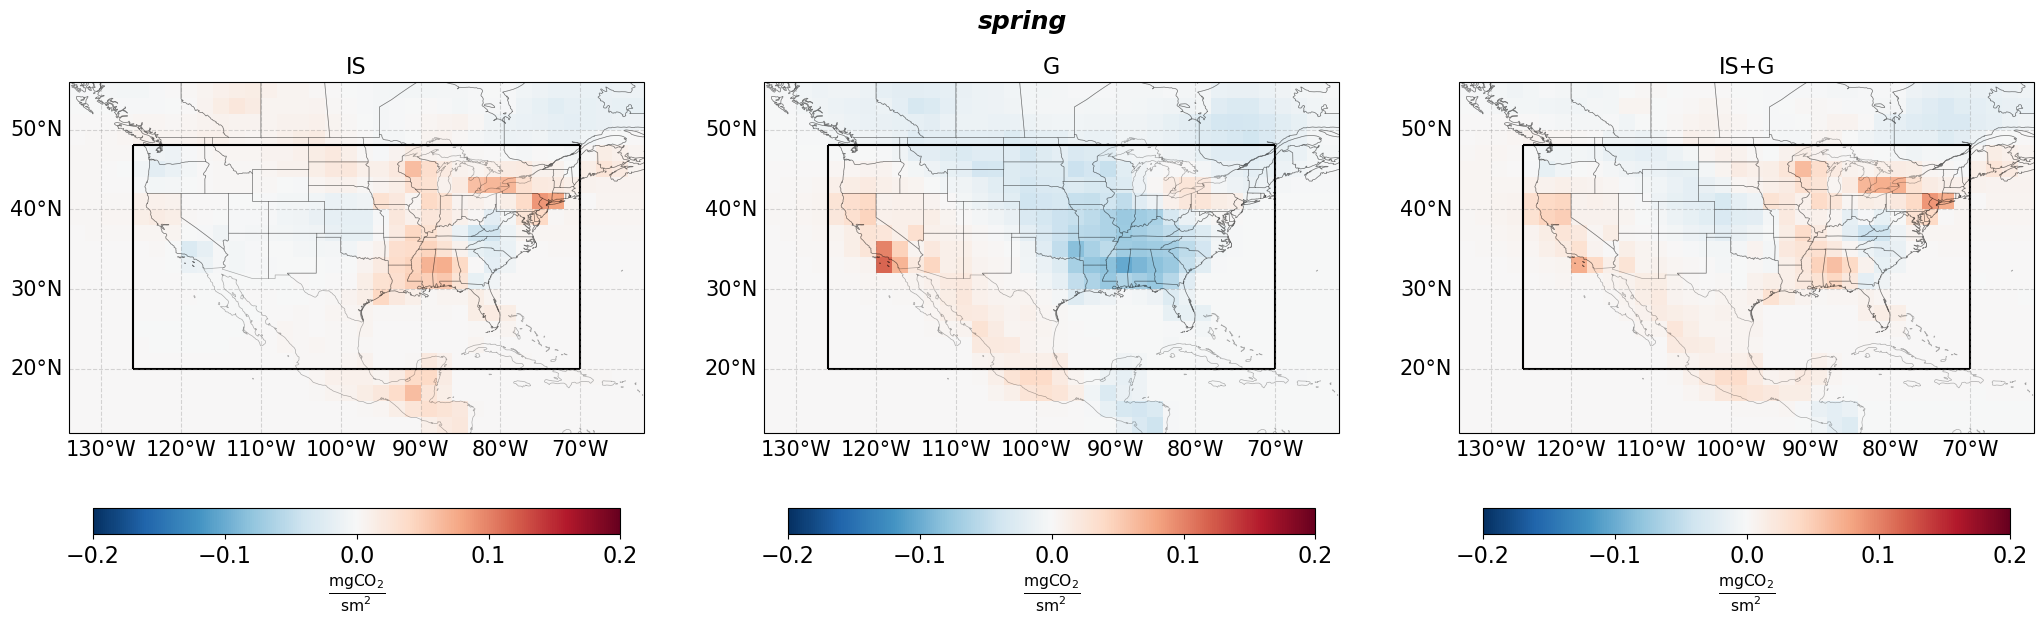

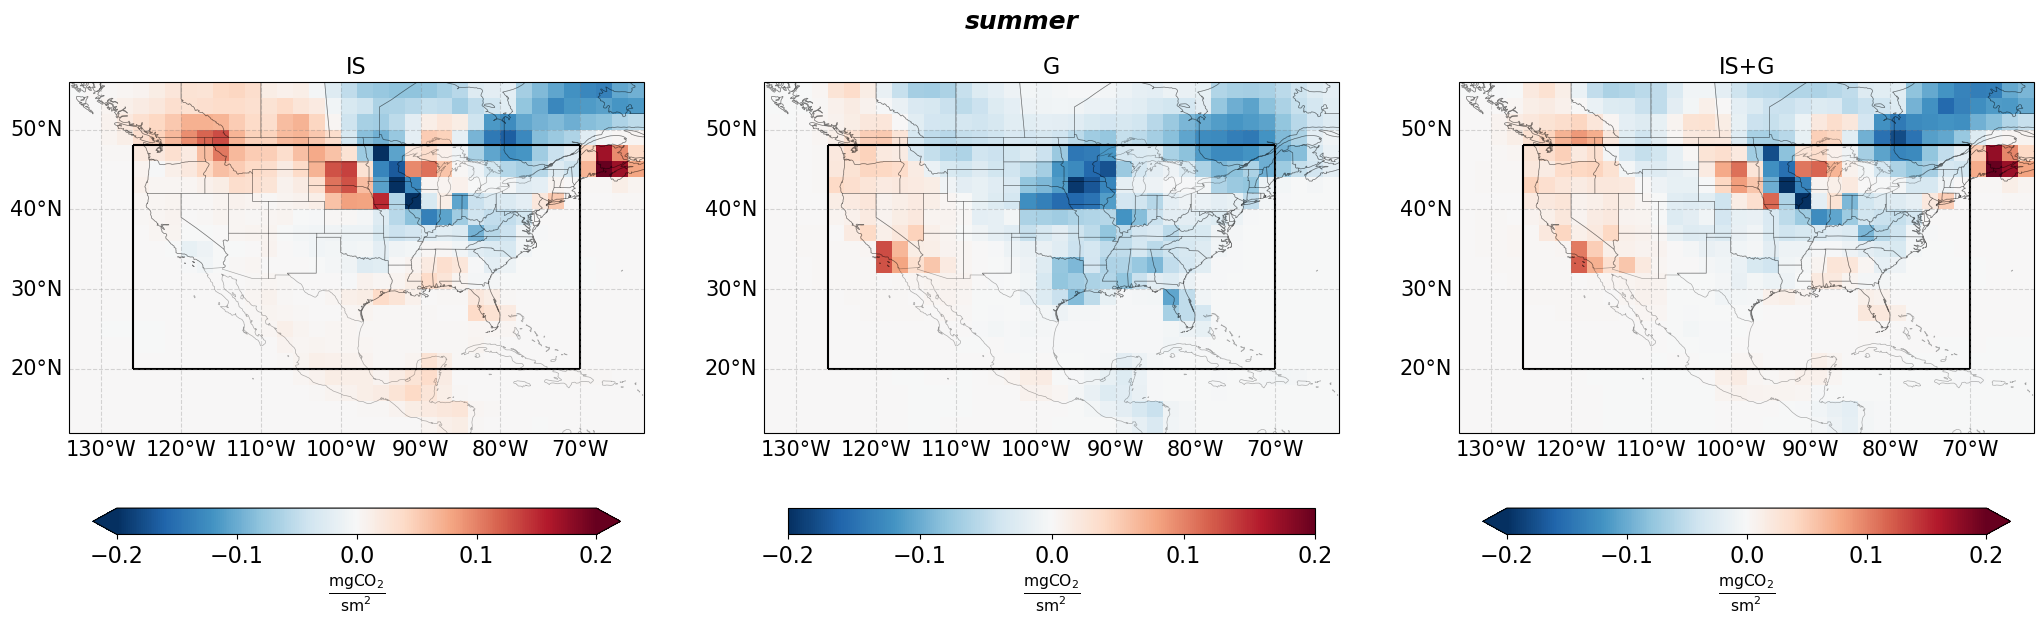

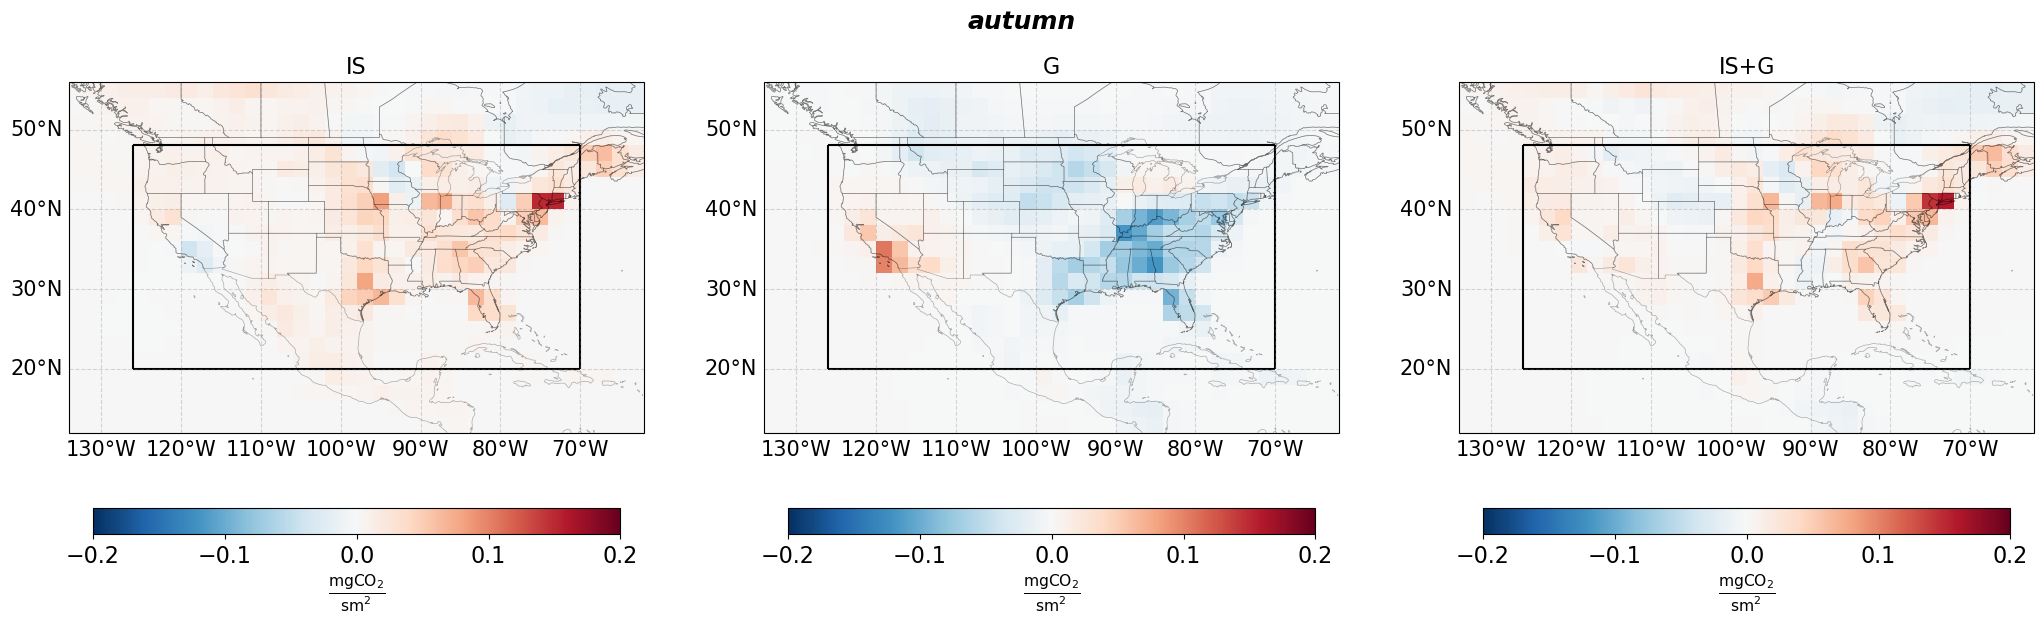

In [75]:
k=0
cmap= LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

for season in seasons:
    fig,axs=plt.subplots(1,3,figsize=(21,6), subplot_kw={'projection': ccrs.PlateCarree()})
    #fig.suptitle("posterior - prior", fontsize=18, fontweight='bold',y=1.04)
    fig.suptitle(f"{season}", fontsize=18, fontweight='bold',style='italic',y=1.03)
    #fig.text(0.5,0.97, f"{season}", ha='center', fontsize=16, style='italic')
    fig.subplots_adjust(right=0.85)
    for i,inversion in enumerate(inversions):
        temp=(fluxes[inversion].TM5_posterior_flux-fluxes[inversion].TM5_prior_flux)*1e6
        temp=temp.where((temp.time.dt.month==seasons[season][0])|(temp.time.dt.month==seasons[season][1])|(temp.time.dt.month==seasons[season][2]), drop=True)     
        plot_map(temp.mean('time'),'$\mathrm{\\frac{mgCO_2}{s m^2}}$',axs[i],vmin=-0.2,vmax=0.2)
        axs[i].set_title(inversion, fontsize=16)
    plt.tight_layout()
    plt.savefig(f'{savefig}/posterior-prior_onlys_{season}.png',bbox_inches='tight',dpi=500)
    plt.show()


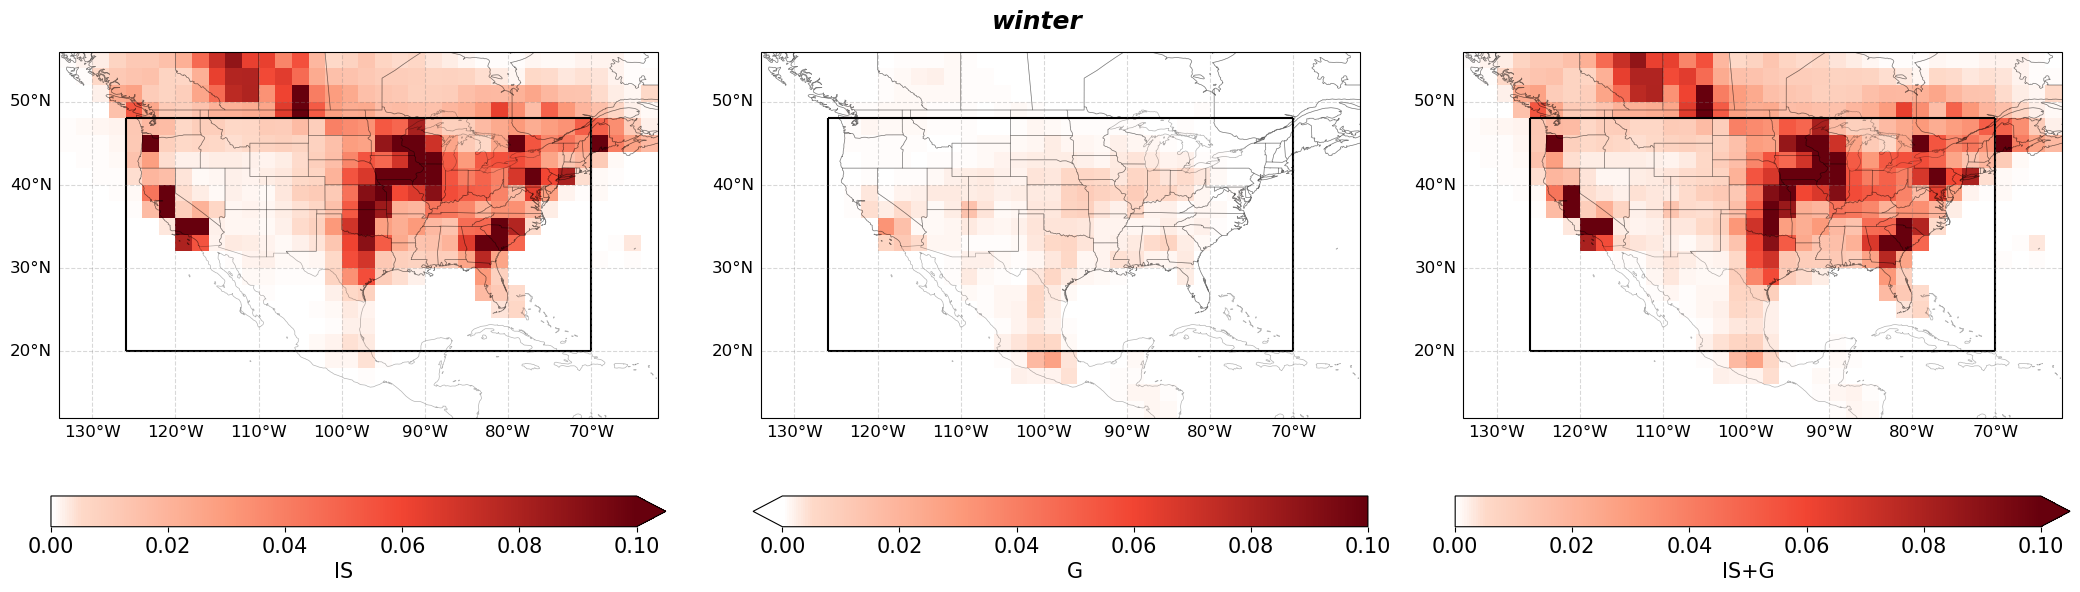

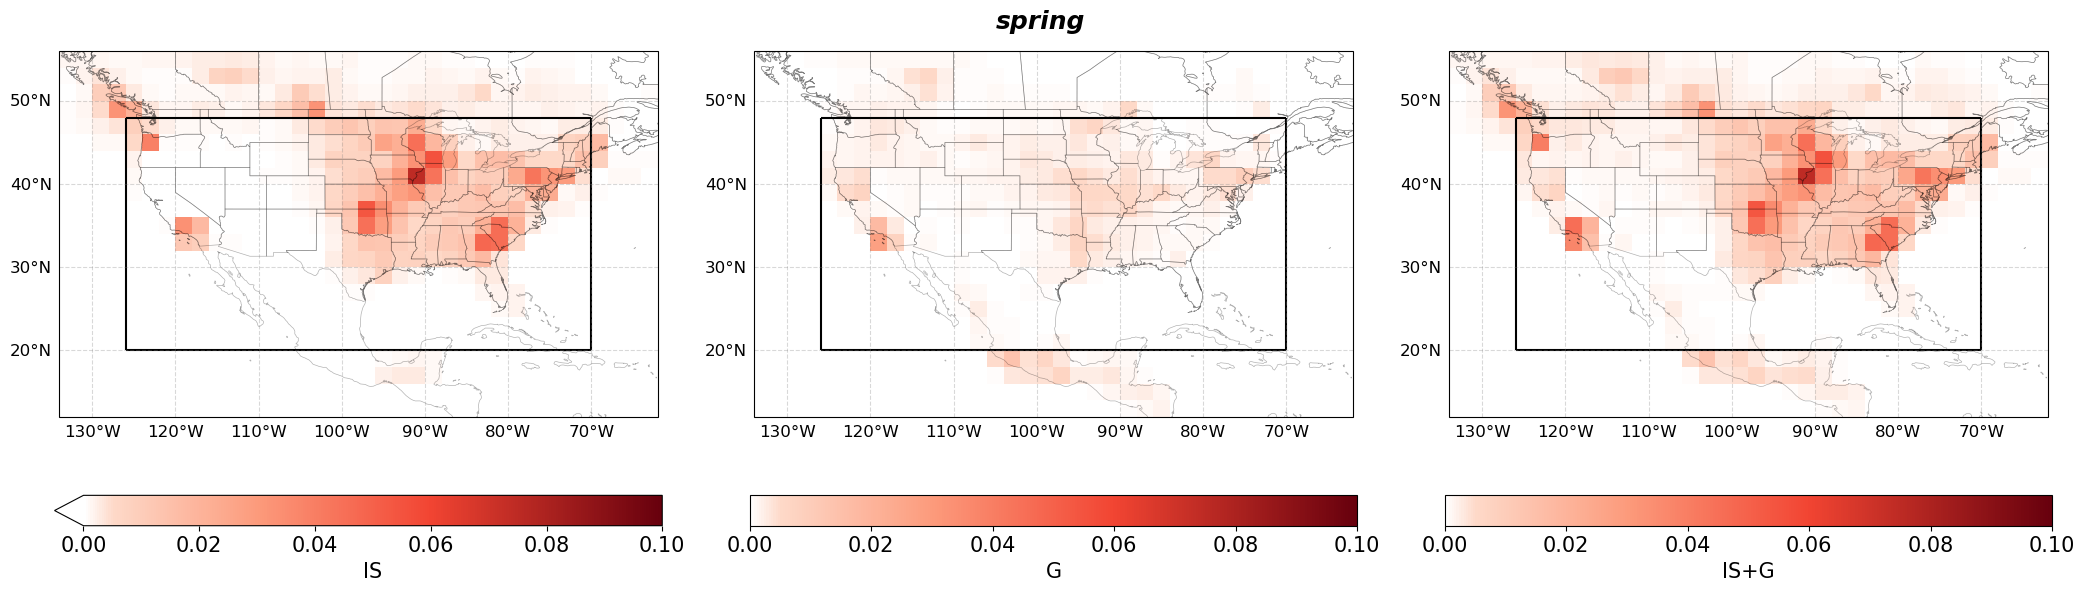

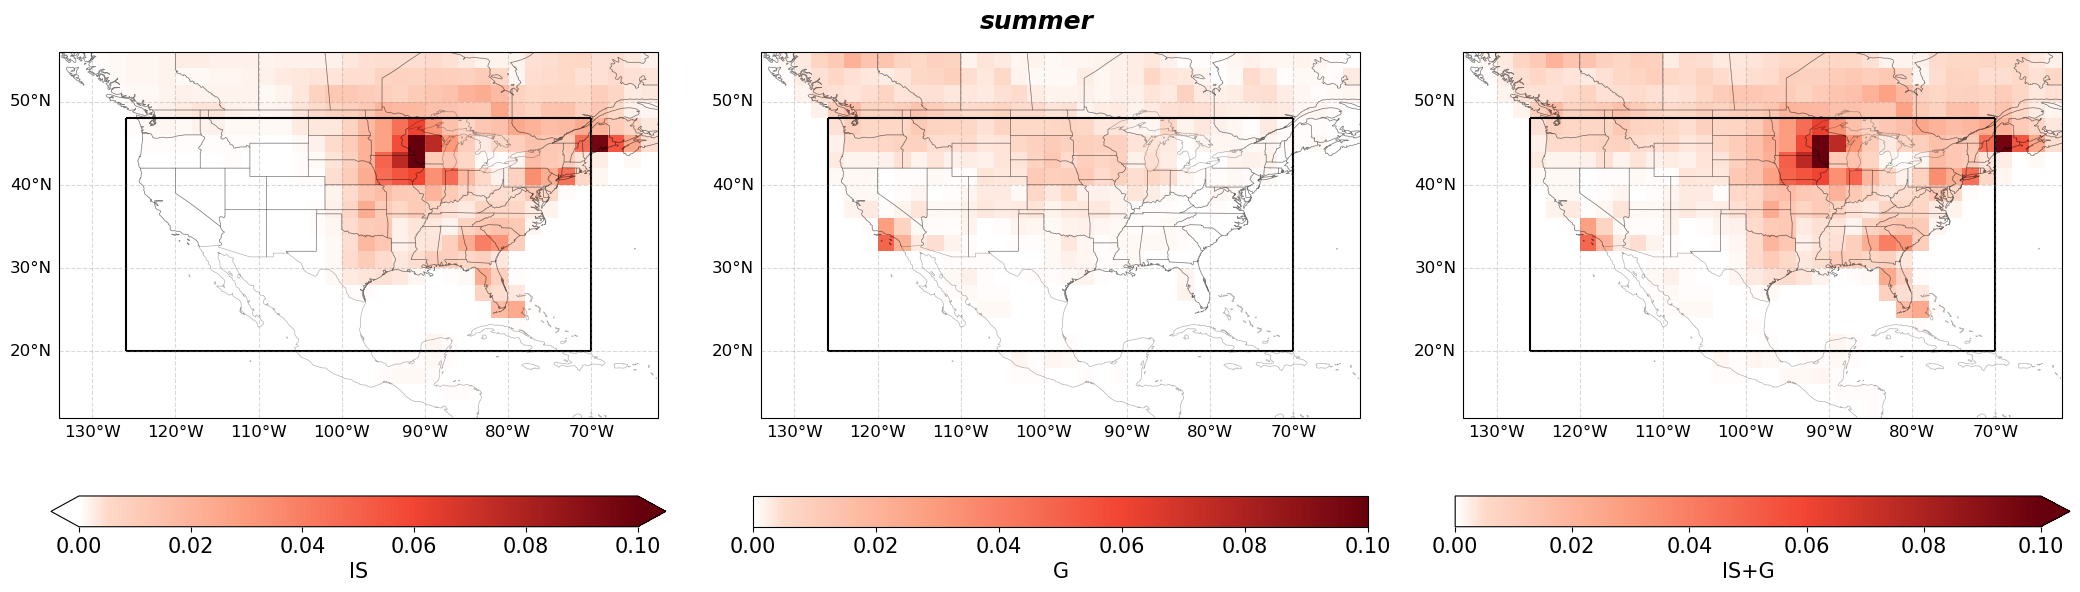

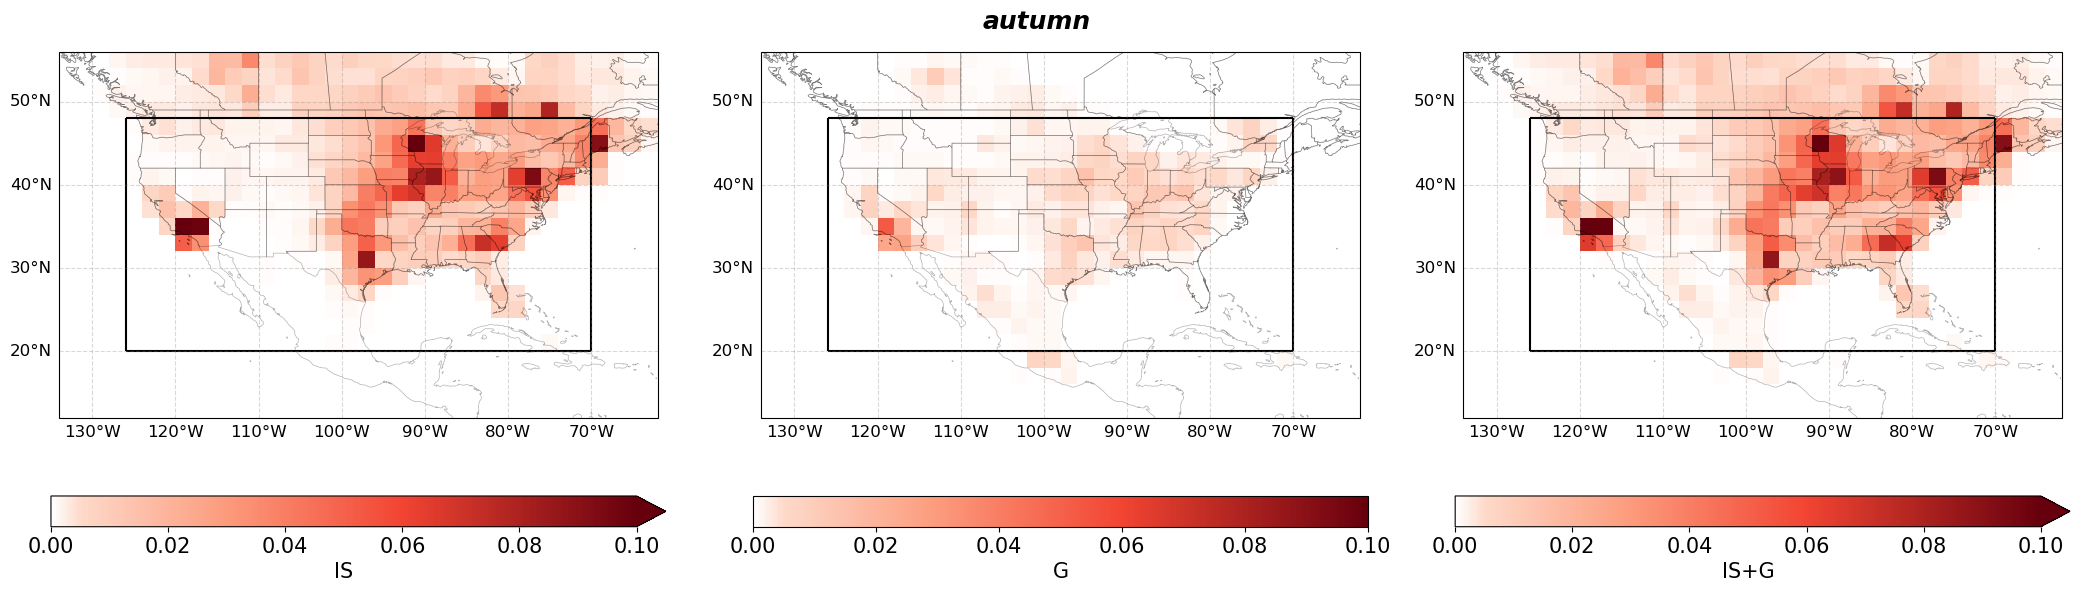

In [83]:
k=0
cmap= LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

for season in seasons:
    fig,axs=plt.subplots(1,3,figsize=(21,6), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"{season}", fontsize=18, fontweight='bold',style='italic')#,y=1.03)
    #fig.text(0.5, 0.92, f"Week of the {str(np.datetime64(week,'D'))}", ha='center', fontsize=12, style='italic')
    fig.subplots_adjust(right=0.85)
    for i,inversion in enumerate(inversions):
        temp=(fluxes[inversion].TM5_averaging_kernel_diag)
        temp=temp.where((temp.time.dt.month==seasons[season][0])|(temp.time.dt.month==seasons[season][1])|(temp.time.dt.month==seasons[season][2]), drop=True) 
        plot_averaging_kernel(temp.mean('time'),inversion,axs[i],vmax=0.1, cmap=cmap)
    plt.tight_layout()
    plt.savefig(f'{savefig}/averaging_kernel_onlys_{season}.png',bbox_inches='tight',dpi=500)
    plt.show()


<>:21: SyntaxWarning: invalid escape sequence '\o'
<>:51: SyntaxWarning: invalid escape sequence '\o'
<>:21: SyntaxWarning: invalid escape sequence '\o'
<>:51: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_885105/705869856.py:21: SyntaxWarning: invalid escape sequence '\o'
  label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
/tmp/ipykernel_885105/705869856.py:51: SyntaxWarning: invalid escape sequence '\o'
  label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'


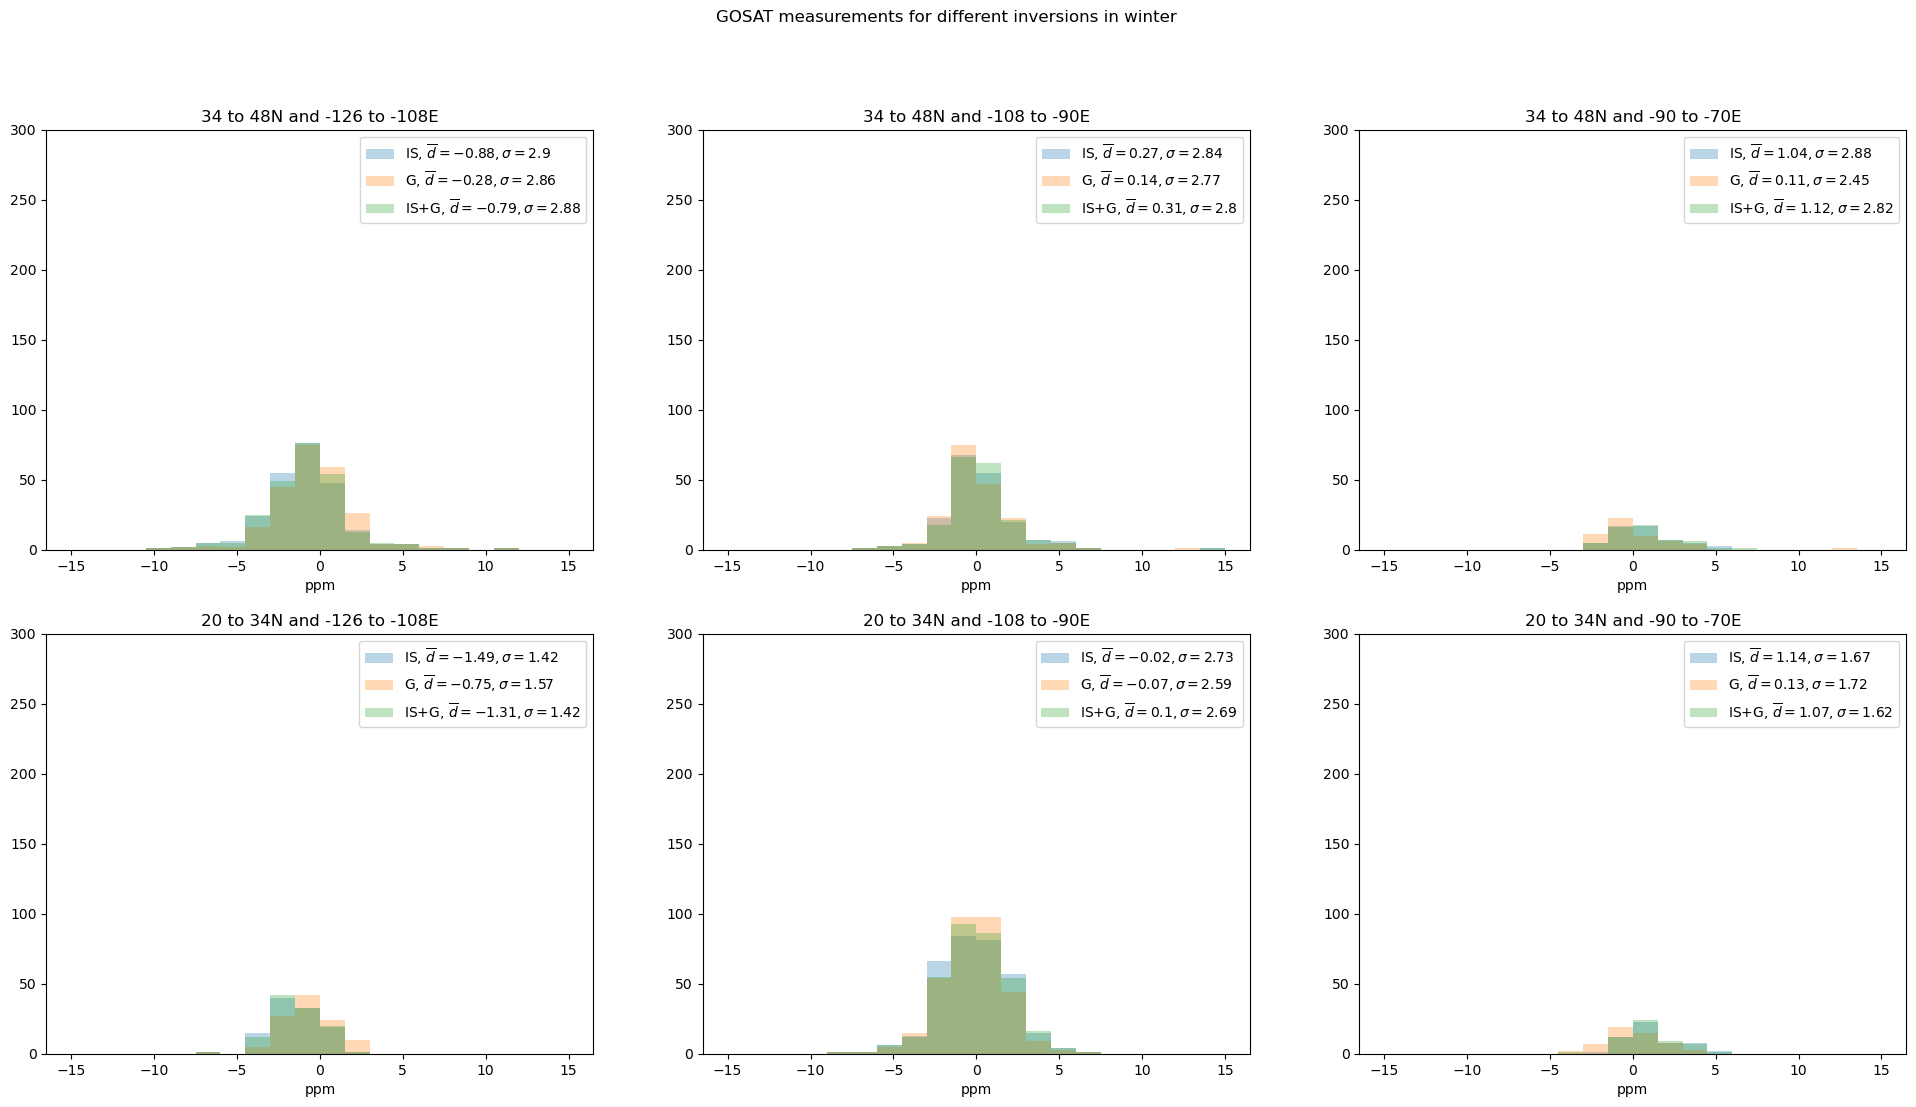

In [149]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
nbins=20
max_min=(-20,20)
title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        for k,inversion in enumerate(['IS','G','IS+G']):
            if False: #g_err==1 or g_err==2 or g_err==3:
                continue
            '''
            temp=insitu_data[inversion]
            temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
            d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
            d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
            d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
            label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
            axs[i,j].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
            axs[i,j].legend()
            axs[i,j].set_xlabel('ppm')
            axs[i,j].set_title(title[0])
            '''
            max_min=(-15,15)
            temp=gosat_data[inversion]
            #temp=temp.where((temp.release_time.dt.month==6) | (temp.release_time.dt.month==7) | (temp.release_time.dt.month==8), drop=True)  #summer
            temp=temp.where((temp.release_time.dt.month==12) | (temp.release_time.dt.month==1) | (temp.release_time.dt.month==2), drop=True) #winter
            temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
            d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
            d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
            d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
            label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
            axs[i,j].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
            axs[i,j].legend()
            axs[i,j].set_xlabel('ppm')
            axs[i,j].set_title(title[1])

            '''
            max_min=(-15,15)
            temp=tccon_data[inversion]
            temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
            d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
            d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
            d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
            label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
            axs[2].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
            axs[2].legend()
            axs[2].set_xlabel('ppm')
            axs[2].set_title(title[2])'''
        axs[i,j].set_ylim(0,300)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        #axs[i,j].tight_layout()
#fig.suptitle('GOSAT measurements for different inversions in summer')
fig.suptitle('GOSAT measurements for different inversions in winter')
#plt.savefig(f'{savefig}/regional_G_hist_comparing_onlys_summer+both.png',bbox_inches='tight')#,transparent=True)
plt.savefig(f'{savefig}/regional_G_hist_comparing_onlys_winter.png',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

<>:49: SyntaxWarning: invalid escape sequence '\o'
<>:63: SyntaxWarning: invalid escape sequence '\o'
<>:49: SyntaxWarning: invalid escape sequence '\o'
<>:63: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_885105/3719619735.py:49: SyntaxWarning: invalid escape sequence '\o'
  label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
/tmp/ipykernel_885105/3719619735.py:63: SyntaxWarning: invalid escape sequence '\o'
  label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/work/bb1170/conda/b383736/envs/inversion/lib/

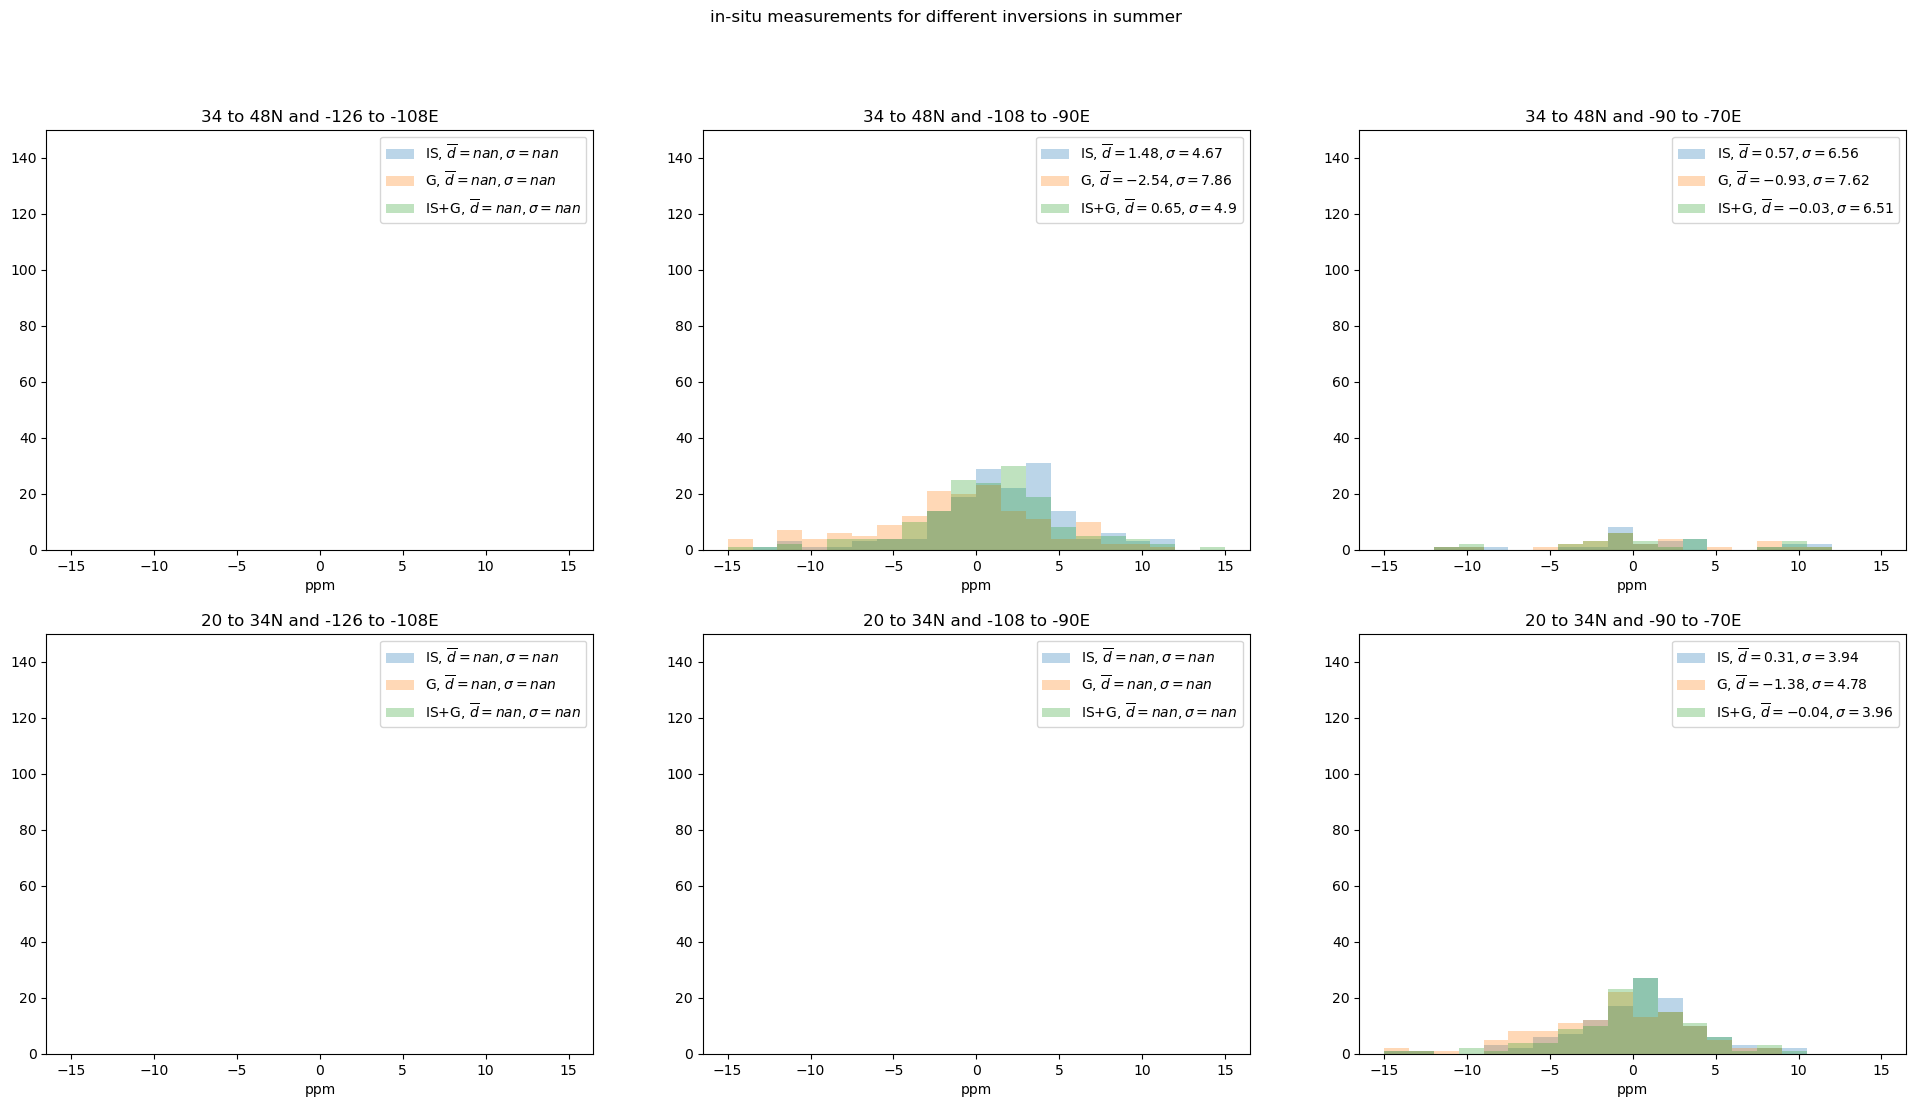

In [151]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
nbins=20
max_min=(-20,20)
title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        for k,inversion in enumerate(['IS','G','IS+G']):
            if False: #g_err==1 or g_err==2 or g_err==3:
                continue
            max_min=(-15,15)
            if inversion=='prior':
                temp=insitu_data['IS']
            else:
                temp=insitu_data[inversion]
            temp=temp.where((temp.release_time.dt.month==6) | (temp.release_time.dt.month==7) | (temp.release_time.dt.month==8), drop=True)  #summer
            #temp=temp.where((temp.release_time.dt.month==12) | (temp.release_time.dt.month==1) | (temp.release_time.dt.month==2), drop=True) #winter
            temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
            if inversion=='prior':
                d0=np.round(np.mean(temp.prior_diff).compute().item(),2)
                d_abs=np.round(np.mean(np.abs(temp.prior_diff)).compute().item(),2)
                d_std=np.round(np.std(temp.prior_diff).compute().item(),2)
                label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
                axs[i,j].hist(temp.prior_diff,alpha=0.3,color='gray', bins=nbins, range=max_min, label=label)
            else:
                d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
                d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
                d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
                label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
                axs[i,j].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
            axs[i,j].legend()
            axs[i,j].set_xlabel('ppm')
            
            '''
            max_min=(-15,15)
            temp=gosat_data[inversion]
            temp=temp.where((temp.release_time.dt.month==6) | (temp.release_time.dt.month==7) | (temp.release_time.dt.month==8), drop=True)  #summer
            #temp=temp.where((temp.release_time.dt.month==12) | (temp.release_time.dt.month==1) | (temp.release_time.dt.month==2), drop=True) #winter
            temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
            d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
            d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
            d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
            label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
            axs[i,j].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
            axs[i,j].legend()
            axs[i,j].set_xlabel('ppm')
            axs[i,j].set_title(title[1])'''

            '''
            max_min=(-15,15)
            temp=tccon_data[inversion]
            temp=temp.where(((temp.release_lat>= regions_lat[-i-2]) &(temp.release_lat<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.release_lon>= regions_lon[j]) &(temp.release_lon<regions_lon[j+1])),drop=True)
            d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
            d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
            d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
            label=label=fr'{inversion}, $\overline{{d}}={d0}, \sigma={d_std}$'
            axs[2].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
            axs[2].legend()
            axs[2].set_xlabel('ppm')
            axs[2].set_title(title[2])'''
        axs[i,j].set_ylim(0,150)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        #axs[i,j].tight_layout()
fig.suptitle('in-situ measurements for different inversions in summer')
#fig.suptitle('in-stu measurements for different inversions in winter')
plt.savefig(f'{savefig}/regional_IS_hist_comparing_onlys_summer+both.png',bbox_inches='tight')#,transparent=True)
#plt.savefig(f'{savefig}/regional_IS_hist_comparing_onlys_winter+both.png',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

In [118]:
insitu_data['IS']


<xarray.Dataset> Size: 1GB
Dimensions:                                              (time: 80,
                                                          pointspec: 1775,
                                                          latitude: 22,
                                                          longitude: 36)
Coordinates:
  * time                                                 (time) datetime64[ns] 640B ...
  * pointspec                                            (pointspec) int64 14kB ...
  * latitude                                             (latitude) float32 88B ...
  * longitude                                            (longitude) float32 144B ...
    height                                               float32 4B 30.0
Data variables: (12/22)
    spec001_mr                                           (time, pointspec, latitude, longitude) float32 450MB ...
    release_num                                          (pointspec) float64 14kB ...
    release_day                                          (pointspec) datetime64[ns] 14kB ...
    Unnamed: 0                                           (pointspec) float64 14kB ...
    release_time                                         (pointspec) datetime64[ns] 14kB ...
    file                                                 (pointspec) object 14kB ...
    ...                                                   ...
    prior_val                                            (pointspec) float64 14kB ...
    posterior_val                                        (pointspec) float64 14kB ...
    ref_RemoteC_IS_val                                   (pointspec) float64 14kB ...
    prior_diff                                           (pointspec) float64 14kB ...
    posterior_diff                                       (pointspec) float64 14kB ...
    ref_RemoteC_IS_diff                                  (pointspec) float64 14kB ...
Attributes: (12/37)
    Conventions:            CF-1.6
    title:                  FLEXPART model output
    git:                    ffadcb5 Fri Sep 19 15:51:15 2025 +0000
    source:                 Version 11.0 (2023-07-11) model output
    history:                2026-07-13 12:42 +0200  created by b383736 on l20...
    references:             Stohl et al., Atmos. Chem. Phys., 2005, doi:10.51...
    ...                     ...
    ind_source:             1
    ind_receptor:           2
    mquasilag:              0
    nested_output:          0
    sfc_only:               0
    linit_cond:             0

In [122]:
months

[6, 7, 8]

(array([468., 167., 114., 116., 100., 104., 108.,  92., 152., 354.]),
 array([ 1. ,  2.1,  3.2,  4.3,  5.4,  6.5,  7.6,  8.7,  9.8, 10.9, 12. ]),
 <BarContainer object of 10 artists>)

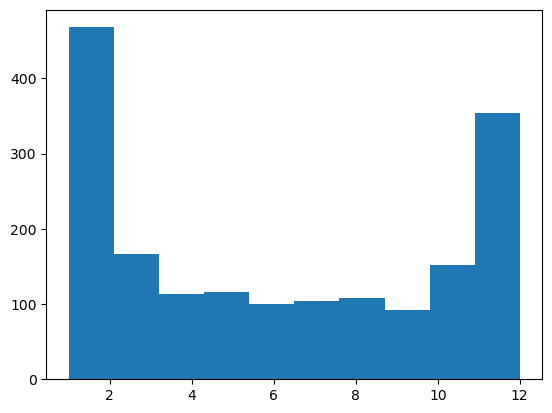

In [123]:
plt.hist(data.release_time.dt.month)

['co2_egb_surface-insitu_6_allvalid.nc'
 'co2_key_surface-flask_1_representative.nc'
 'co2_lef_tower-insitu_1_allvalid-396magl.nc'
 'co2_lew_surface-pfp_1_allvalid-95magl.nc'
 'co2_mwo_surface-pfp_1_allvalid-46magl.nc'
 'co2_omp_surface-insitu_68_allhours.nc'
 'co2_sct_surface-pfp_1_allvalid-305magl.nc'
 'co2_sct_tower-insitu_1_allvalid-305magl.nc'
 'co2_sgp_surface-flask_1_representative.nc'
 'co2_sgp_surface-insitu_64_allvalid-60magl.nc'
 'co2_wbi_surface-pfp_1_allvalid-379magl.nc'
 'co2_wbi_tower-insitu_1_allvalid-379magl.nc'
 'co2_wgc_tower-insitu_1_allvalid-484magl.nc'
 'co2_wkt_tower-insitu_1_allvalid-457magl.nc']
co2_lef_tower-insitu_1_allvalid-396magl.nc
co2_sct_tower-insitu_1_allvalid-305magl.nc
co2_wbi_tower-insitu_1_allvalid-379magl.nc
co2_wgc_tower-insitu_1_allvalid-484magl.nc
co2_wkt_tower-insitu_1_allvalid-457magl.nc


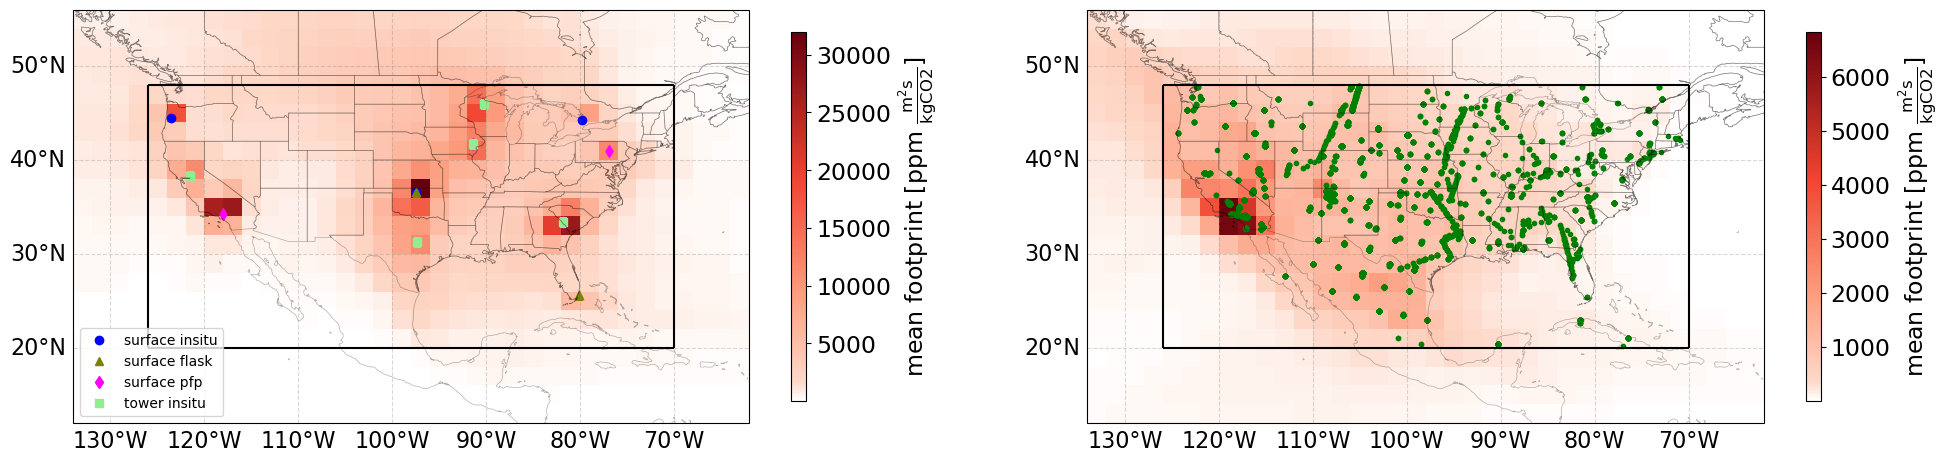

In [14]:

flexpart_region=[12,56,-134,-62]

from mpl_toolkits.axes_grid1 import make_axes_locatable


# ---------------------------------------------------------
# Figure layout
# ---------------------------------------------------------

fig,(ax_IS,ax_gosat)=plt.subplots(1,2,figsize=(24,12), subplot_kw={'projection': ccrs.PlateCarree()})

# ---------------------------------------------------------
# IS
# ---------------------------------------------------------
cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])
# 0 -> white, 120 -> dark green
norm = Normalize(vmin=0, vmax=120)
#lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)
data=insitu_data['IS']
plot=data.spec001_mr.drop_vars('height').mean('pointspec').mean('time').plot(ax=ax_IS,cmap=cmap,rasterized=True, cbar_kwargs={'location':'right', 'label':r'mean footprint [ppm $\mathrm{\frac{m^2s}{kgCO2}}$]','shrink':0.4, 'aspect':25, 'pad':0.05})
print(np.unique(data.file))

plot.colorbar.ax.yaxis.label.set_size(17)
plot.colorbar.ax.tick_params(labelsize=17)
ax_IS.coastlines(linewidth=0.5, alpha=0.3)
ax_IS.add_feature( cfeature.STATES, edgecolor='black', linewidth=0.5, alpha=0.3)
gl = ax_IS.gridlines( draw_labels=True, color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
ax_IS.set_xlim(-134, -62)
ax_IS.set_ylim(12, 56)
ax_IS.tick_params(axis='both', labelsize=20)

ax_IS.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax_IS.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax_IS.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax_IS.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')

fig.canvas.draw()

files=[f for f in np.unique(data.file.values)]
# distinguish between surface and tower, insitu and flask
surf_is=[f for f in files if 'surface-insitu' in f]
surf_pfp=[f for f in files if 'surface-pfp' in f]
surf_flask=[f for f in files if 'surface-flask' in f]   # all flask meas
tower_is=[f for f in files if 'tower-insitu' in f]
release=data.drop_dims(['time','latitude','longitude'])
for f in surf_is:
    temp=release.where(release.file==f,drop=True)
    ax_IS.scatter(temp.release_lon[0], temp.release_lat[0], marker='o', color='blue')
for f in surf_flask:
    temp=release.where(release.file==f,drop=True)
    ax_IS.scatter(temp.release_lon[0], temp.release_lat[0], marker='^', color='olive')
for f in surf_pfp:
    temp=release.where(release.file==f,drop=True)
    ax_IS.scatter(temp.release_lon[0], temp.release_lat[0], marker='d', color='magenta')
for f in tower_is:
    print(f)
    temp=release.where(release.file==f,drop=True)
    ax_IS.scatter(temp.release_lon[0], temp.release_lat[0], marker='s', color='lightgreen')
# Manually create legend handles
custom_legend = [
    Line2D([0], [0], marker='o', label='surface insitu',color='blue', linestyle=''),
    Line2D([0], [0], marker='^', label='surface flask',color='olive', linestyle=''),
    Line2D([0], [0], marker='d', label='surface pfp',color='magenta', linestyle=''),
    Line2D([0], [0], marker='s', label='tower insitu',color='lightgreen', linestyle='')
]
# Add custom legend
ax_IS.legend(handles=custom_legend, loc='lower left', fontsize=10)


# ---------------------------------------------------------
# GOSAT
# ---------------------------------------------------------
cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])
# 0 -> white, 120 -> dark green
norm = Normalize(vmin=0, vmax=120)
#lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)
data=gosat_data['IS']
plot=data.spec001_mr.drop_vars('height').mean('pointspec').mean('time').plot(ax=ax_gosat,cmap=cmap, rasterized=True,
                                                                             cbar_kwargs={'location':'right', 'label':r'mean footprint [ppm $\mathrm{\frac{m^2s}{kgCO2}}$]','shrink':0.4, 'aspect':25, 'pad':0.05})
plot.colorbar.ax.yaxis.label.set_size(17)
plot.colorbar.ax.tick_params(labelsize=17)
ax_gosat.coastlines(linewidth=0.5, alpha=0.3)
ax_gosat.add_feature( cfeature.STATES, edgecolor='black', linewidth=0.5, alpha=0.3)
gl = ax_gosat.gridlines( draw_labels=True, color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
ax_gosat.set_xlim(-134, -62)
ax_gosat.set_ylim(12, 56)
ax_gosat.tick_params(axis='both', labelsize=20)

ax_gosat.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax_gosat.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax_gosat.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax_gosat.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')

fig.canvas.draw()


release=data.drop_dims(['time','latitude','longitude'])
ax_gosat.scatter(release.release_lon, release.release_lat, marker='.', color='green')

# Manually create legend handles
custom_legend = [
    Line2D([0], [0], marker='o', label='surface insitu',color='blue', linestyle=''),
    Line2D([0], [0], marker='^', label='surface flask',color='olive', linestyle=''),
    Line2D([0], [0], marker='d', label='surface pfp',color='magenta', linestyle=''),
    Line2D([0], [0], marker='s', label='tower insitu',color='lightgreen', linestyle='')
]


plt.savefig(f'{savefig}/coverage.pdf',bbox_inches='tight')#,transparent=True)

plt.show()

['co2_key_surface-flask_1_representative.nc'
 'co2_lef_tower-insitu_1_allvalid-396magl.nc'
 'co2_lew_surface-pfp_1_allvalid-95magl.nc'
 'co2_sct_surface-pfp_1_allvalid-305magl.nc'
 'co2_sct_tower-insitu_1_allvalid-305magl.nc'
 'co2_sgp_surface-flask_1_representative.nc'
 'co2_sgp_surface-insitu_64_allvalid-60magl.nc'
 'co2_wbi_surface-pfp_1_allvalid-379magl.nc']
co2_lef_tower-insitu_1_allvalid-396magl.nc
co2_sct_tower-insitu_1_allvalid-305magl.nc


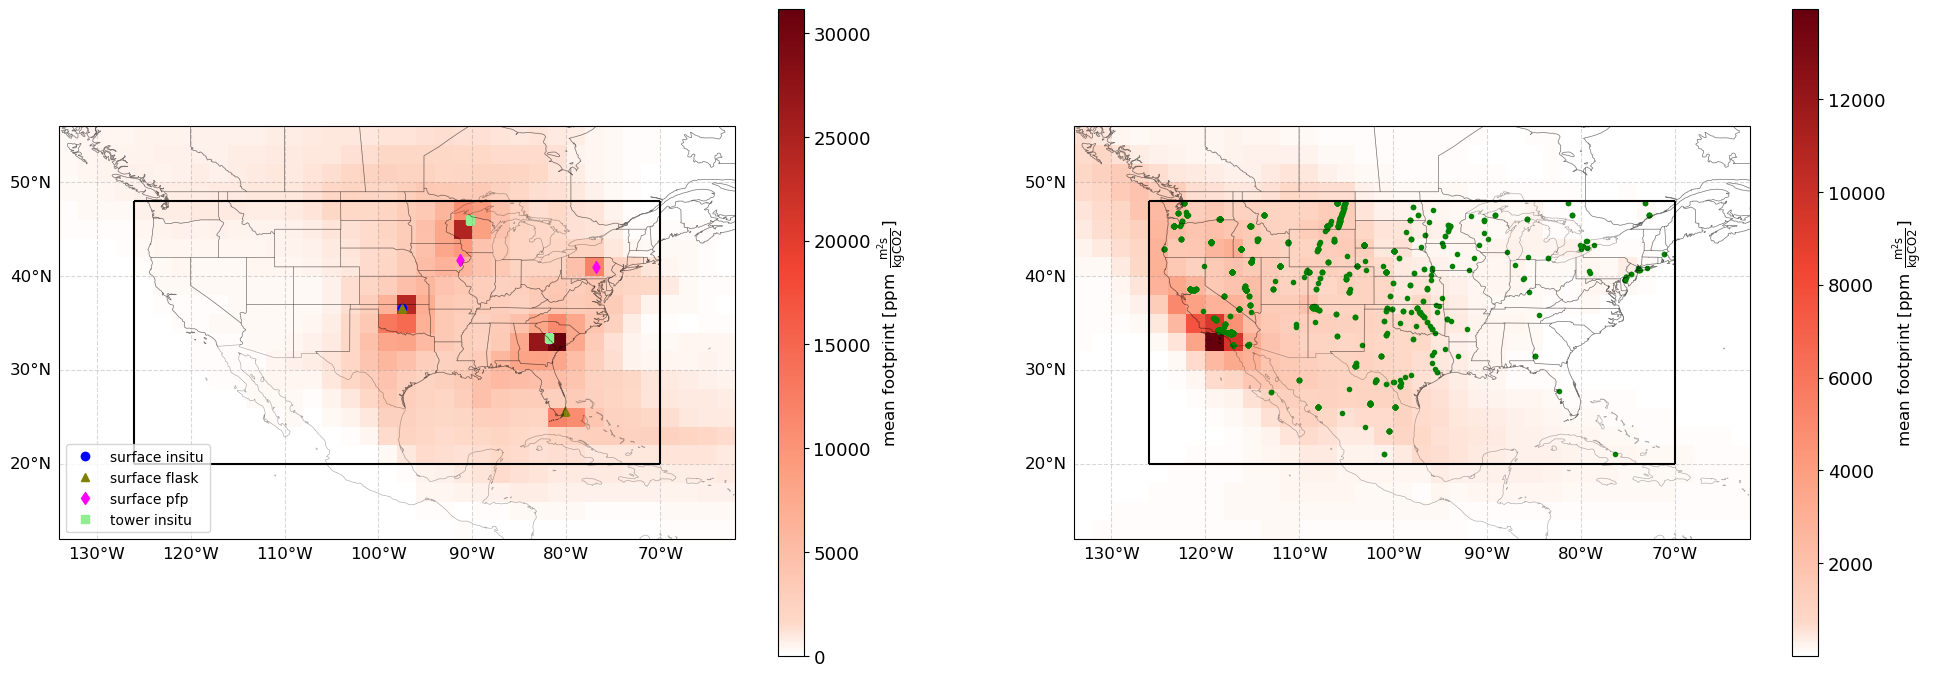

In [71]:
#months=[12,1,2] #winter
months=[6,7,8]  #summer

flexpart_region=[12,56,-134,-62]

from mpl_toolkits.axes_grid1 import make_axes_locatable


# ---------------------------------------------------------
# Figure layout
# ---------------------------------------------------------

fig,(ax_IS,ax_gosat)=plt.subplots(1,2,figsize=(24,12), subplot_kw={'projection': ccrs.PlateCarree()})

# ---------------------------------------------------------
# IS
# ---------------------------------------------------------
cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])
# 0 -> white, 120 -> dark green
norm = Normalize(vmin=0, vmax=120)
#lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)
data=insitu_data['IS']
data=data.where((data.release_time.dt.month==months[0]) | (data.release_time.dt.month==months[1]) | (data.release_time.dt.month==months[2]), drop=True)  #summer
plot=data.spec001_mr.drop_vars('height').mean('pointspec').mean('time').plot(ax=ax_IS,cmap=cmap, cbar_kwargs={'location':'right', 'label':r'mean footprint [ppm $\mathrm{\frac{m^2s}{kgCO2}}$]','shrink':0.7, 'aspect':25, 'pad':0.05})
print(np.unique(data.file))

plot.colorbar.ax.yaxis.label.set_size(12)
plot.colorbar.ax.tick_params(labelsize=13)
ax_IS.coastlines(linewidth=0.5, alpha=0.3)
ax_IS.add_feature( cfeature.STATES, edgecolor='black', linewidth=0.5, alpha=0.3)
gl = ax_IS.gridlines( draw_labels=True, color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}
ax_IS.set_xlim(-134, -62)
ax_IS.set_ylim(12, 56)
ax_IS.tick_params(axis='both', labelsize=20)

ax_IS.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax_IS.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax_IS.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax_IS.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')

fig.canvas.draw()

files=[f for f in np.unique(data.file.values)]
# distinguish between surface and tower, insitu and flask
surf_is=[f for f in files if 'surface-insitu' in f]
surf_pfp=[f for f in files if 'surface-pfp' in f]
surf_flask=[f for f in files if 'surface-flask' in f]   # all flask meas
tower_is=[f for f in files if 'tower-insitu' in f]
release=data.drop_dims(['time','latitude','longitude'])
for f in surf_is:
    temp=release.where(release.file==f,drop=True)
    ax_IS.scatter(temp.release_lon[0], temp.release_lat[0], marker='o', color='blue')
for f in surf_flask:
    temp=release.where(release.file==f,drop=True)
    ax_IS.scatter(temp.release_lon[0], temp.release_lat[0], marker='^', color='olive')
for f in surf_pfp:
    temp=release.where(release.file==f,drop=True)
    ax_IS.scatter(temp.release_lon[0], temp.release_lat[0], marker='d', color='magenta')
for f in tower_is:
    print(f)
    temp=release.where(release.file==f,drop=True)
    ax_IS.scatter(temp.release_lon[0], temp.release_lat[0], marker='s', color='lightgreen')
# Manually create legend handles
custom_legend = [
    Line2D([0], [0], marker='o', label='surface insitu',color='blue', linestyle=''),
    Line2D([0], [0], marker='^', label='surface flask',color='olive', linestyle=''),
    Line2D([0], [0], marker='d', label='surface pfp',color='magenta', linestyle=''),
    Line2D([0], [0], marker='s', label='tower insitu',color='lightgreen', linestyle='')
]
# Add custom legend
ax_IS.legend(handles=custom_legend, loc='lower left', fontsize=10)


# ---------------------------------------------------------
# GOSAT
# ---------------------------------------------------------
cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])
# 0 -> white, 120 -> dark green
norm = Normalize(vmin=0, vmax=120)
#lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)
data=gosat_data['IS']
data=data.where((data.release_time.dt.month==months[0]) | (data.release_time.dt.month==months[1]) | (data.release_time.dt.month==months[2]), drop=True)  #summer
plot=data.spec001_mr.drop_vars('height').mean('pointspec').mean('time').plot(ax=ax_gosat,cmap=cmap, 
                                                                             cbar_kwargs={'location':'right', 'label':r'mean footprint [ppm $\mathrm{\frac{m^2s}{kgCO2}}$]','shrink':0.7, 'aspect':25, 'pad':0.05})
plot.colorbar.ax.yaxis.label.set_size(12)
plot.colorbar.ax.tick_params(labelsize=13)
ax_gosat.coastlines(linewidth=0.5, alpha=0.3)
ax_gosat.add_feature( cfeature.STATES, edgecolor='black', linewidth=0.5, alpha=0.3)
gl = ax_gosat.gridlines( draw_labels=True, color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}
ax_gosat.set_xlim(-134, -62)
ax_gosat.set_ylim(12, 56)
ax_gosat.tick_params(axis='both', labelsize=20)

ax_gosat.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax_gosat.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax_gosat.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax_gosat.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')

fig.canvas.draw()


release=data.drop_dims(['time','latitude','longitude'])
ax_gosat.scatter(release.release_lon, release.release_lat, marker='.', color='green')

# Manually create legend handles
custom_legend = [
    Line2D([0], [0], marker='o', label='surface insitu',color='blue', linestyle=''),
    Line2D([0], [0], marker='^', label='surface flask',color='olive', linestyle=''),
    Line2D([0], [0], marker='d', label='surface pfp',color='magenta', linestyle=''),
    Line2D([0], [0], marker='s', label='tower insitu',color='lightgreen', linestyle='')
]


plt.savefig(f'{savefig}/coverage_summer.png',bbox_inches='tight')#,transparent=True)

plt.show()